<a href="https://colab.research.google.com/github/DinRazar/data-data/blob/main/%D0%A0%D0%B0%D0%B1%D0%BE%D1%82%D0%B0_4.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# ****Практическая работа. Геоанализ экологических факторов городской среды с применением методов пространственной кластеризации****

В этой работе вы не просто запускаете готовый алгоритм кластеризации. Главная задача — **самостоятельно построить логику исследования**: выбрать территорию, подобрать релевантные OSM-теги, превратить пространственные объекты в числовые признаки, осознанно выбрать алгоритм кластеризации и интерпретировать полученные группы территорий.

## ****Цель работы****

Освоить полный цикл пространственной кластеризации городской территории: от выбора экологически значимых признаков и OSM-тегов до построения H3-сетки, расчёта признаков, сравнения алгоритмов кластеризации и содержательной интерпретации кластеров.

---

## ****Что должно получиться в конце****

По итогам работы у вас должны быть:

1. Обоснованно выбранная территория исследования.
2. Таблица экологических признаков и OSM-тегов, которые вы используете для их загрузки.
3. H3-сетка, покрывающая выбранную территорию.
4. Набор числовых признаков для каждой H3-ячейки.
5. Сравнение нескольких алгоритмов кластеризации.
6. Карта кластеров.
7. Содержательная типология территорий: не просто «кластер 0 / кластер 1», а названия вроде «зелёные рекреационные зоны», «транспортно нагруженные территории», «промышленно-коммунальные зоны» и т.д.
8. Краткие рекомендации по улучшению экологической ситуации для каждого типа территории.

## ****Основной принцип работы****

Код в этом блокноте — это **заготовка**, а не готовый ответ.



Оценивается не то, насколько точно вы скопировали код (он уже скопирован по большей части), а то, насколько осмысленно вы приняли исследовательские решения:

- почему выбрали именно эту территорию;
- почему эти OSM-теги подходят для вашей задачи;
- какие признаки вы рассчитали и зачем;
- почему выбрали такое разрешение H3-сетки;
- почему использовали именно эти алгоритмы кластеризации;
- почему итоговые кластеры можно интерпретировать именно так.



Кластеризация — это метод без заранее известных правильных ответов. Поэтому качество результата определяется не только метриками, но и **смыслом полученных групп**.

## ****Перед началом****

Перед выполнением практической работы повторите материал занятия по кластерному анализу:



- зачем нужна нормализация признаков;
- чем отличаются K-means, агломеративная кластеризация, спектральная кластеризация, DBSCAN и HDBSCAN;
- как читать Silhouette Score, Calinski–Harabasz Index и Davies–Bouldin Index;
- почему один «лучший» алгоритм не всегда существует;
- как интерпретировать кластеры через средние значения признаков.



Ссылка на материалы занятий:


**Ознакомиться обязательно!**


- Методы машинного обучения без учителя: https://clck.ru/3Tn8A4


- Машинное обучение для пространственного анализа городской инфраструктуры: кластеризация и сравнительный анализ алгоритмов: https://clck.ru/3Tn8DM


---

# ****Часть 1. Постановка исследовательской задачи****

## ****1.1. Выбор территории исследования****

Выберите город или часть города для анализа. Это может быть:

- весь город;
- промышленный район;
- территория вдоль крупной автомагистрали;
- новая застройка;
- исторический центр;
- территория вокруг реки или водоёма;
- пригородная зона на границе городской и природной среды.

Важно, чтобы в выбранной территории потенциально были **разные типы экологической ситуации**. Если вся территория однородна, кластеризация может оказаться малоинформативной.

### ****Ответьте перед началом анализа****

Заполните этот блок текстом.

1. Какую территорию вы выбрали?
2. Почему эта территория интересна для экологического анализа?
3. Какие различия внутри территории вы ожидаете увидеть?
4. Какие экологические проблемы могут быть характерны для этой территории?
5. Какой масштаб анализа вам нужен: крупные зоны города, районы, кварталы?



1. Территория: город Дзержинск Нижегородской области (городской округ, включая селитебную часть и крупные промышленные узлы).

2. Почему интересна: Дзержинск — исторически крупный центр химической промышленности. Здесь сочетаются плотная жилая застройка, несколько крупных промышленных зон (Восточная промзона, ОЭЗ «Кулибин», индустриальный парк «Заря» и др.) и одновременно значительные зелёные массивы (дендропарк, сосновые леса, пойменные дубравы). Это создаёт сильный пространственный контраст экологической ситуации.

3. Ожидаемые различия: ожидаю увидеть как минимум три типа территорий: (а) промышленно-транспортные зоны с высокой нагрузкой, (б) селитебные зоны с混合ной нагрузкой, (в) относительно благополучные зелёные/рекреационные и водно-зелёные территории.

4. Экологические проблемы: повышенный уровень загрязнения атмосферного воздуха (в 2025 году уровень оценивался как «высокий», фиксировались превышения по фенолу и формальдегиду), наличие крупной химической свалки «Чёрная дыра», высокая концентрация промышленных объектов, транспортная нагрузка вдоль магистралей.

5. Масштаб анализа: уровень города и крупных планировочных зон (селитебная часть, промышленные узлы, рекреационные массивы). Для H3-сетки это будет соответствовать разрешению 8 или 9.



---

In [3]:
%%capture
# Установка библиотек для Google Colab.
# Если вы работаете локально и библиотеки уже установлены, эту ячейку можно пропустить.

!pip install -q geopandas shapely pyproj
!pip install -q osmnx leafmap
!pip install -q "h3>=3.7,<4" h3pandas
!pip install -q scikit-learn matplotlib seaborn mapclassify kneed hdbscan

In [5]:
!pip install "h3>=3.7,<4"
!pip install h3pandas

  Using cached h3-3.7.7.tar.gz (192 kB)
  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Preparing metadata (pyproject.toml) ... done
  error: subprocess-exited-with-error
  
  × Building wheel for h3 (pyproject.toml) did not run successfully.
  │ exit code: 1
  ╰─> No available output.
  
  note: This error originates from a subprocess, and is likely not a problem with pip.
  ERROR: Failed building wheel for h3
Failed to build h3
error: failed-wheel-build-for-install

× Failed to build installable wheels for some pyproject.toml based projects
╰─> h3
  Using cached h3pandas-0.3.0-py3-none-any.whl.metadata (2.0 kB)
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.1/1.1 MB 11.0 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2/2 [h3pandas]


In [6]:
# Импорт библиотек

import warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import geopandas as gpd
import matplotlib.pyplot as plt
import seaborn as sns

from shapely.geometry import box, Polygon
from shapely.ops import unary_union

import osmnx as ox
import leafmap
import h3

from sklearn.preprocessing import MinMaxScaler, StandardScaler
from sklearn.cluster import KMeans, AgglomerativeClustering, SpectralClustering, DBSCAN
from sklearn.metrics import silhouette_score, calinski_harabasz_score, davies_bouldin_score
from sklearn.decomposition import PCA
from sklearn.neighbors import NearestNeighbors

try:
    from google.colab import output
    output.enable_custom_widget_manager()
except Exception:
    pass

try:
    from kneed import KneeLocator
except Exception:
    KneeLocator = None

## ****1.2. Выбор области интереса на карте****

Нарисуйте прямоугольник или полигон вокруг выбранной территории. После этого выполните следующую ячейку, чтобы получить `bbox`.

Если интерактивная карта не работает, можно вручную задать координаты в формате:



```python
bbox = [west, south, east, north]
```



где:

- `west` — западная долгота;
- `south` — южная широта;
- `east` — восточная долгота;
- `north` — северная широта.

In [7]:
# При надобности, измените центр карты под свой город.

CENTER_LAT = 56.2376
CENTER_LON = 43.4599
ZOOM = 11

m = leafmap.Map(center=[CENTER_LAT, CENTER_LON], zoom=ZOOM, draw_control=True)
m

Map(center=[56.2376, 43.4599], controls=(ZoomControl(options=['position', 'zoom_in_text', 'zoom_in_title', 'zo…

In [8]:
# Получаем bbox из нарисованной области.
# Если область не нарисована, используется примерный bbox для Москвы.

bbox = m.user_roi_bounds()

if bbox:
    print("Выбранный bbox:", bbox)
else:
    bbox = [43.35, 56.18, 43.57, 56.30]  # Замените на свою территорию
    print("ROI не выбран на карте. Используется bbox по умолчанию:", bbox)

west, south, east, north = bbox

ROI не выбран на карте. Используется bbox по умолчанию: [43.35, 56.18, 43.57, 56.3]


## ****1.3. Формулировка экологических признаков****

Перед загрузкой данных нужно определить, **какие явления городской среды вы считаете экологически значимыми**.

Пример логики:

| Шаг | Вопрос | Пример |
|---|---|---|
| 1 | Какой экологический признак анализируем? | Транспортная нагрузка |
| 2 | Какие объекты в OSM отражают этот признак? | Магистрали, крупные дороги |
| 3 | Какие теги подходят? | `highway=motorway`, `highway=trunk`, `highway=primary` |
| 4 | Какой пространственный признак считаем? | Длина дорог в буфере 1600 м |
| 5 | Как влияет на экологию? | Негативно |

Ваша задача — выбрать **не менее 5 признаков**, при этом желательно, чтобы среди них были и позитивные, и негативные.

## ****Подсказки по выбору OSM-тегов****

OSM-тег обычно имеет вид `ключ=значение`, например:

- `leisure=park` — парк;
- `landuse=industrial` — промышленная зона;
- `highway=primary` — крупная дорога;
- `natural=water` — водный объект.



Полезные источники для проверки тегов:

- https://wiki.openstreetmap.org/wiki/RU:Объекты_карты
- https://wiki.openstreetmap.org/wiki/Map_features
- https://taginfo.openstreetmap.org/



Не выбирайте теги механически. Один и тот же экологический признак может быть представлен несколькими тегами. Например, зелёные зоны могут быть описаны через `leisure=park`, `landuse=forest`, `natural=wood`, `landuse=grass`, `leisure=garden`.

## ****Примеры признаков и тегов****

Эта таблица дана как пример. Вы можете использовать её, но должны адаптировать под свою территорию и задачу.



| Фактор | Возможные OSM-теги | Типичный расчётный признак | Влияние |
|---|---|---|---|
| Зелёные зоны | `leisure=park`, `leisure=garden`, `landuse=forest`, `natural=wood`, `landuse=grass` | площадь зелёных зон в буфере | Позитивное |
| Водные объекты | `natural=water`, `waterway=river`, `waterway=stream` | площадь или протяжённость воды | Позитивное |
| Промышленные территории | `landuse=industrial`, `man_made=works` | площадь промышленных зон, количество объектов | Негативное |
| Энергетическая инфраструктура | `power=plant`, `power=generator`, `power=substation` | количество объектов или площадь | Часто негативное / зависит от типа |
| Магистрали | `highway=motorway`, `highway=trunk`, `highway=primary`, `highway=secondary` | длина дорог в буфере | Негативное |
| Железные дороги | `railway=rail` | протяжённость железных дорог | Негативное или нейтральное по контексту |
| Мусорные и коммунальные объекты | `landuse=landfill`, `amenity=waste_disposal`, `amenity=recycling` | количество или площадь объектов | Обычно негативное, но требует пояснения |
| Рекреационная инфраструктура | `leisure=nature_reserve`, `tourism=picnic_site` | количество/площадь объектов | Позитивное |



**Важно:** некоторые теги могут давать мало объектов или не отражать нужный смысл в вашем городе. После загрузки обязательно проверьте, что именно найдено.

### ****Ваша таблица признаков****

Заполните таблицу. Не ограничивайтесь названиями тегов — объясните, почему они подходят.


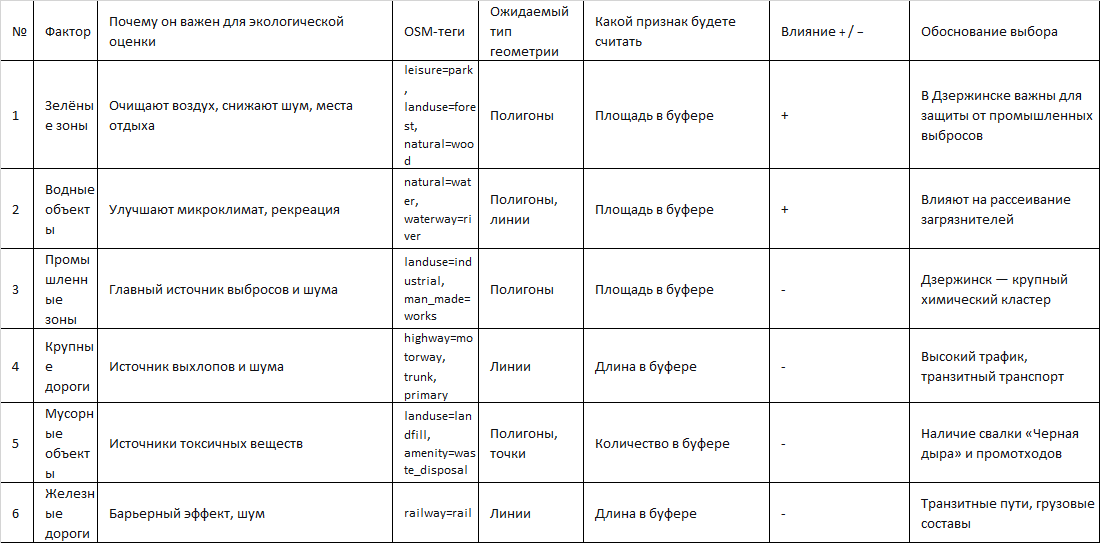

## ****1.4. Перевод выбранных признаков в словарь для загрузки OSM****

Ниже дана заготовка. Измените её так, чтобы она соответствовала вашей таблице признаков.

Обратите внимание:

- название слоя должно быть понятным: `green`, `industry`, `major_roads`, `water`;
- в `tags` указываются OSM-теги;
- в `influence` указывается направление влияния: `+` для позитивного, `-` для негативного, `mixed` если влияние зависит от контекста;
- в `reason` напишите короткое объяснение, зачем этот слой нужен.

In [9]:
FACTOR_CATALOG = {
    "green": {
        "name": "Зелёные зоны",
        "tags": {"leisure": ["park", "garden"], "landuse": ["forest", "grass", "meadow"], "natural": ["wood"]},
        "influence": "+",
        "reason": "Зелёные зоны улучшают экологический комфорт."
    },
    "water": {
        "name": "Водные объекты",
        "tags": {"natural": ["water"], "waterway": ["river", "stream", "canal"]},
        "influence": "+",
        "reason": "Водные объекты улучшают микроклимат."
    },
    "industry": {
        "name": "Промышленные территории",
        "tags": {"landuse": ["industrial"], "man_made": ["works"]},
        "influence": "-",
        "reason": "Источник выбросов и шума."
    },
    "major_roads": {
        "name": "Крупные дороги",
        "tags": {"highway": ["motorway", "trunk", "primary", "secondary"]},
        "influence": "-",
        "reason": "Транспортная нагрузка, выбросы."
    },
    "waste": {
        "name": "Мусорные объекты",
        "tags": {"landuse": ["landfill"], "amenity": ["waste_disposal"]},
        "influence": "-",
        "reason": "Источники токсичных веществ."
    },
    "railways": {
        "name": "Железные дороги",
        "tags": {"railway": ["rail"]},
        "influence": "-",
        "reason": "Шум и барьерный эффект."
    }
}
print("Количество выбранных признаков:", len(FACTOR_CATALOG))

Количество выбранных признаков: 6


### ****Проверка смысла выбранных тегов****

Перед загрузкой данных ответьте:

1. Какие теги вы оставили из примера?
2. Какие теги добавили самостоятельно?
3. Какие теги исключили и почему?
4. Есть ли среди ваших признаков такие, где влияние неоднозначно?
5. Что вы будете делать, если по выбранному тегу в OSM окажется мало объектов?



**ВАШ ОТВЕТ:**

Из примера я оставил зелёные зоны, воду, промышленность и дороги. Добавил железные дороги для оценки транспортной нагрузки и уточнил мусорные объекты (landfill), так как для Дзержинска это критически важный фактор. Если тег landfill даст мало объектов, я расширю его. Влияние воды и зелени — однозначно позитивное, промышленности и дорог — негативное.



---

# ****Часть 2. Загрузка и проверка данных из OpenStreetMap****

## ****2.1. Функция загрузки данных****

Функция ниже загружает каждый слой из `FACTOR_CATALOG`. Она также создаёт пустой `GeoDataFrame`, если по выбранным тегам ничего не найдено. Это важно: пустой слой — не ошибка кода, а сигнал, что нужно проверить теги или выбранную территорию.

In [10]:
def features_from_bbox_compat(bbox, tags):  # Функция-обёртка для совместимости с разными версиями OSMnx
    """
    Совместимый вызов OSMnx для разных версий библиотеки.
    bbox задаётся как [west, south, east, north].
    """
    west, south, east, north = bbox  # Распаковка координат bbox
    try:  # Попытка вызова для OSMnx >= 2.0 (bbox как кортеж)
        return ox.features_from_bbox((west, south, east, north), tags=tags)  # Передаём bbox одним аргументом
    except TypeError:  # Если формат не подошёл — пробуем старый API
        try:  # Попытка вызова для OSMnx < 2.0 (отдельные координаты)
            return ox.features_from_bbox(north, south, east, west, tags)  # Передаём координаты по отдельности
        except TypeError:  # Если и это не сработало — именованный аргумент
            return ox.features_from_bbox(bbox=(west, south, east, north), tags=tags)  # Явно указываем bbox=


def load_osm_layers(bbox, factor_catalog, crs_out="EPSG:3857"):  # Загрузка нескольких слоёв OSM по каталогу
    """
    Загружает слои OSM по словарю признак -> теги.
    Возвращает словарь GeoDataFrame-ов в метрической проекции.
    """
    data = {}  # Словарь для хранения загруженных слоёв

    for layer_key, params in factor_catalog.items():  # Итерация по всем слоям в каталоге
        print(f"\nЗагрузка слоя: {layer_key} — {params['name']}")  # Лог: имя текущего слоя
        print("Теги:", params["tags"])  # Лог: теги для запроса

        try:  # Блок обработки ошибок загрузки
            gdf = features_from_bbox_compat(bbox, params["tags"])  # Загрузка объектов из OSM
            if gdf is None or gdf.empty:  # Проверка на пустой результат
                print("  Нет объектов по выбранным тегам.")  # Лог: данных нет
                data[layer_key] = gpd.GeoDataFrame(columns=["geometry"], geometry="geometry", crs=crs_out)  # Пустой GeoDataFrame
                continue  # Переход к следующему слою

            gdf = gdf.reset_index()  # Сброс индекса (OSMnx возвращает MultiIndex)
            gdf = gdf[gdf.geometry.notna()].copy()  # Удаление строк без геометрии
            gdf = gdf.set_geometry("geometry")  # Явное указание столбца геометрии

            if gdf.crs is None:  # Проверка наличия CRS
                gdf = gdf.set_crs("EPSG:4326")  # Установка WGS84 по умолчанию (стандарт OSM)

            gdf = gdf.to_crs(crs_out)  # Перепроецирование в целевую метрическую CRS
            gdf = gdf[gdf.geometry.is_valid]  # Фильтрация невалидных геометрий
            data[layer_key] = gdf  # Сохранение слоя в словарь
            print(f"  Загружено объектов: {len(gdf)}")  # Лог: количество загруженных объектов

        except Exception as e:  # Обработка любых исключений
            print(f"  Ошибка загрузки слоя {layer_key}: {e}")  # Лог: сообщение об ошибке
            data[layer_key] = gpd.GeoDataFrame(columns=["geometry"], geometry="geometry", crs=crs_out)  # Пустой GeoDataFrame при ошибке

    return data  # Возврат словаря со всеми слоями

In [11]:
# Загрузка выбранных признаков

crs_proj = "EPSG:3857"
data = load_osm_layers(bbox, FACTOR_CATALOG, crs_out=crs_proj)


Загрузка слоя: green — Зелёные зоны
Теги: {'leisure': ['park', 'garden'], 'landuse': ['forest', 'grass', 'meadow'], 'natural': ['wood']}
  Ошибка загрузки слоя green: 'overpass-api.de' responded: 502 Bad Gateway # 502 Gateway Timeout

This Overpass API server is currently at capacity. All query workers are busy
and the request queue is full.

## What to do

Retry your request using exponential backoff: wait a short interval, then retry.
If the request fails again, double the wait time and retry again.

## For heavy or automated use

This public endpoint is intended for browser-based and human-operated tools.
For automated or high-volume use, run a local Overpass API instance:

https://github.com/b1tw153/Overpass-API/blob/main/README.md


Загрузка слоя: water — Водные объекты
Теги: {'natural': ['water'], 'waterway': ['river', 'stream', 'canal']}
  Загружено объектов: 174

Загрузка слоя: industry — Промышленные территории
Теги: {'landuse': ['industrial'], 'man_made': ['works']}
  Ошибка

## ****2.2. Первичная проверка загруженных слоёв****

После загрузки важно проверить не только количество объектов, но и типы геометрии.

Почему это важно:

- площадь можно корректно считать только для полигонов;
- длину — для линий;
- количество — почти для любых объектов;
- расстояние до ближайшего объекта можно считать для любых геометрий, но смысл результата зависит от признака.

In [12]:
def layer_summary(data, factor_catalog):  # Функция для создания сводной таблицы по загруженным слоям
    rows = []  # Список для накопления строк будущего DataFrame
    for key, gdf in data.items():  # Итерация по всем загруженным слоям
        geom_types = [] if gdf.empty else sorted(gdf.geometry.geom_type.dropna().unique().tolist())  # Список уникальных типов геометрий (или пустой, если слой пуст)
        rows.append({  # Добавление словаря с метаданными слоя
            "layer": key,  # Ключ слоя (идентификатор)
            "name": factor_catalog[key]["name"],  # Человекочитаемое название слоя из каталога
            "objects": len(gdf),  # Количество объектов в слое
            "geometry_types": ", ".join(geom_types),  # Типы геометрий через запятую (Point, Polygon и т.д.)
            "influence": factor_catalog[key]["influence"],  # Тип влияния фактора (позитивный/негативный)
            "reason": factor_catalog[key]["reason"]  # Обоснование влияния фактора
        })  # Конец словаря
    return pd.DataFrame(rows)  # Преобразование списка словарей в DataFrame

summary_df = layer_summary(data, FACTOR_CATALOG)  # Вызов функции для создания сводки
summary_df  # Вывод DataFrame

,layer,name,objects,geometry_types,influence,reason
0,green,Зелёные зоны,0,,+,Зелёные зоны улучшают экологический комфорт.
1,water,Водные объекты,174,"LineString, Polygon",+,Водные объекты улучшают микроклимат.
2,industry,Промышленные территории,0,,-,Источник выбросов и шума.
3,major_roads,Крупные дороги,189,LineString,-,"Транспортная нагрузка, выбросы."
4,waste,Мусорные объекты,62,"Point, Polygon",-,Источники токсичных веществ.
5,railways,Железные дороги,315,LineString,-,Шум и барьерный эффект.


### ****Интерпретация проверки данных****

Ответьте после просмотра таблицы:

1. Какие слои загрузились хорошо?
2. Какие слои почти пустые или пустые?
3. Какие теги нужно заменить или расширить?
4. Какие признаки представлены в OSM полигонами, а какие линиями или точками?
5. Какие признаки теперь логично считать для каждого слоя?



**ВАШ ОТВЕТ:**
Вообще не загрузились загрузились слои «industry» (промышленность) и «green» (зелень) возможно их нет. Слой «waste» может оказаться малочисленным, но даже несколько найденных свалок/полигонов критически важны. Дороги и ж/д представлены линиями. Площадь логично считать для зелени, воды, промышленности и свалок, а длину — для дорог.



---

In [17]:
# Дополнительный просмотр первых строк выбранного слоя.
# Замените layer_to_view на интересующий вас слой.

layer_to_view = "major_roads"

if layer_to_view in data and not data[layer_to_view].empty:
    display(data[layer_to_view].head())
else:
    print("Слой пустой или отсутствует:", layer_to_view)

,element,id,geometry,highway,maxspeed,hgv,lanes,lit,name,surface,...,trolley_wire,amenity,junction,bridge,bridge:name,layer,sidewalk:both,lane_markings,turn:lanes,hgv:backward
0,way,23885204,"LINESTRING (4838123.637 7606228.218, 4838130.8...",secondary,RU:urban,destination,2,yes,проспект Чкалова,asphalt,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,way,23886201,"LINESTRING (4830256.756 7603706.773, 4830237.2...",secondary,RU:urban,NaN,2,NaN,проспект Циолковского,asphalt,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,way,23886444,"LINESTRING (4829957.618 7602325.522, 4829904.6...",secondary,NaN,NaN,2,no,Решетихинское шоссе,asphalt,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
3,way,24215012,"LINESTRING (4843676.487 7606729.822, 4843702.3...",secondary,RU:urban,NaN,2,NaN,Автозаводское шоссе,asphalt,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
4,way,24939167,"LINESTRING (4838192.555 7606138.918, 4838222.0...",secondary,NaN,destination,NaN,yes,проспект Дзержинского,asphalt,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


## ****2.3. Быстрая карта загруженных объектов****

Эта карта нужна не для итогового отчёта, а для проверки: действительно ли OSM-запросы вернули объекты в нужной зоне.

In [18]:
# Быстрая визуальная проверка слоёв.
check_map = leafmap.Map(center=[(south + north) / 2, (west + east) / 2], zoom=11)  # Создание интерактивной карты с центром в середине bbox

for key, gdf in data.items():  # Итерация по всем загруженным слоям
    if gdf is None or gdf.empty:  # Пропуск пустых или отсутствующих слоёв
        continue  # Переход к следующему слою

    # Для отображения переводим обратно в EPSG:4326
    gdf_wgs = gdf.to_crs("EPSG:4326")  # Перепроецирование в WGS84 (требуется для leaflet-карт)

    # Оставляем только геометрию + основные поля, чтобы не перегружать интерактивную карту
    keep_cols = [c for c in gdf_wgs.columns if c in ("name", "geometry")]  # Фильтр: только name и geometry
    gdf_wgs = gdf_wgs[keep_cols].copy()  # Создание облегчённой копии GeoDataFrame

    check_map.add_gdf(  # Добавление слоя на карту [[5]]
        gdf_wgs,  # GeoDataFrame для отображения
        layer_name=f"{key}: {FACTOR_CATALOG[key]['name']}",  # Название слоя в панели управления
    )  # Конец добавления слоя

    break  # Прерывание после первого слоя (для быстрой проверки)

check_map  # Отображение карты

Map(center=[56.239999999999995, 43.46], controls=(ZoomControl(options=['position', 'zoom_in_text', 'zoom_in_ti…

# ****Часть 3. Построение H3-сетки****

## ****3.1. Выбор разрешения H3****

H3-сетка задаёт пространственную единицу анализа. Слишком крупные ячейки сгладят различия, слишком мелкие — дадут много нулевых значений и шум.



Ориентиры:



| H3 resolution | Примерный масштаб | Когда использовать |
|---|---|---|
| 7 | крупные городские зоны | большой город целиком, региональный обзор |
| 8 | районный уровень | город или крупный район |
| 9 | квартальный уровень | детальный анализ части города |
| 10 | очень детальный уровень | небольшая территория, но возрастает шум и вычислительная нагрузка |



Выберите разрешение и объясните, почему оно соответствует вашей задаче.

### ****Обоснование выбора H3-разрешения****

1. Какое разрешение вы выбрали?
2. Какой масштаб анализа оно отражает?
3. Не слишком ли крупные или мелкие получаются ячейки?
4. Как выбранное разрешение связано с радиусами буферов, которые вы будете использовать?



**ВАШ ОТВЕТ:**



Я выбираю разрешение 8. Для площади Дзержинска это даст адекватное количество ячеек (около 200-300). Это районный масштаб, который позволит увидеть крупные промышленные узлы, но не разобьет город на слишком мелкие куски с нулевыми значениями. Радиус буферов 800-1600 м хорошо соотносится с размером одной ячейки.

In [24]:
# Выберите разрешение и обоснуйте его в текстовой ячейке выше.

H3_RESOLUTION = 8

In [29]:
def make_h3_grid_from_bbox(bbox, resolution, crs_out="EPSG:3857"):
    west, south, east, north = bbox
    bbox_polygon = box(west, south, east, north)

    # 1. В h3 v4 функция polyfill называется polygon_to_cells (или geo_to_cells)
    # Используем geo_to_cells для GeoJSON-объекта
    h3_indexes = list(h3.geo_to_cells(bbox_polygon.__geo_interface__, resolution))

    # 2. В h3 v4 h3_to_geo_boundary заменена на cell_to_boundary
    # Она возвращает (lat, lng), а для Shapely Polygon нужен (lng, lat)
    h3_geometries = []
    for h in h3_indexes:
        boundary_lat_lng = h3.cell_to_boundary(h)
        # Меняем порядок координат на (lng, lat)
        boundary_lng_lat = [(lng, lat) for lat, lng in boundary_lat_lng]
        h3_geometries.append(Polygon(boundary_lng_lat))

    h3_gdf = gpd.GeoDataFrame(
        {"h3_index": h3_indexes, "geometry": h3_geometries},
        crs="EPSG:4326"
    ).to_crs(crs_out)

    return h3_gdf

h3_gdf = make_h3_grid_from_bbox(bbox, H3_RESOLUTION, crs_out=crs_proj)
print("Количество H3-ячеек:", len(h3_gdf))
h3_gdf.head()

Количество H3-ячеек: 251


,h3_index,geometry
0,881016cecdfffff,"POLYGON ((4826347.156 7611406.737, 4826801.737..."
1,881016cc95fffff,"POLYGON ((4844519.654 7607547.53, 4844972.685 ..."
2,881016cc07fffff,"POLYGON ((4833157.546 7598792.819, 4833610.938..."
3,881016cea9fffff,"POLYGON ((4831905.043 7608127.112, 4832359.036..."
4,881016cc2bfffff,"POLYGON ((4833130.264 7597091.031, 4833583.565..."


In [30]:
# Карта H3-сетки для проверки масштаба

grid_map = leafmap.Map(center=[(south + north) / 2, (west + east) / 2], zoom=11)  # Создание интерактивной карты с центром в середине bbox
grid_map.add_gdf(  # Добавление GeoDataFrame на карту
    h3_gdf.to_crs("EPSG:4326"),  # Перепроецирование H3-сетки в WGS84 (требуется для Leaflet)
    layer_name=f"H3 grid resolution {H3_RESOLUTION}"  # Название слоя с указанием разрешения сетки
)  # Конец добавления слоя
grid_map  # Отображение карты в Jupyter Notebook

Map(center=[56.239999999999995, 43.46], controls=(ZoomControl(options=['position', 'zoom_in_text', 'zoom_in_ti…

### ****Проверка масштаба сетки****

Посмотрите на карту и ответьте:

1. Видны ли различия внутри территории на выбранной сетке?
2. Не слишком ли много/мало ячеек получилось?
3. Нужно ли изменить `H3_RESOLUTION`?
4. Какие экологические объекты могут оказаться «размытыми» из-за выбранного размера ячейки?



**ВАШ ОТВЕТ:**
На карте видно, что сетка покрывает весь город. Количество ячеек оптимально для анализа. Мелкие объекты (отдельные скверы или предприятия) могут усредняться внутри ячейки, но для общей экологической типологии города это допустимо.


---

# ****Часть 4. Инженерия пространственных признаков****

## ****4.1. Что такое признак в этой работе****

Кластеризация работает не с картой напрямую, а с таблицей чисел. Поэтому каждый пространственный признак нужно превратить в числовой признак для каждой H3-ячейки.



Примеры:



| Фактор | Возможный признак | Почему так |
|---|---|---|
| Зелёные зоны | площадь зелёных зон в буфере 800 м | показывает доступность зелёной инфраструктуры рядом с ячейкой |
| Промзоны | площадь промышленных территорий в буфере 1600 м | отражает потенциальную промышленную нагрузку |
| Магистрали | длина крупных дорог в буфере 1600 м | отражает транспортную нагрузку |
| Вода | площадь/длина водных объектов в буфере | отражает рекреационный и микроклиматический потенциал |
| Свалки | расстояние до ближайшего объекта | важно не только количество, но и близость |



Буфер вокруг ячейки нужен, потому что экологическое воздействие редко ограничивается границами одного гексагона.

## ****4.2. Выбор метрик расчёта признаков****

Выберите метрику под тип объекта:



| Метрика | Когда использовать | Пример |
|---|---|---|
| `count` | когда важно количество объектов | число ТЭЦ, число мусорных объектов |
| `area` | для полигональных объектов | площадь парков, промзон, водоёмов |
| `share` | когда нужна доля площади в буфере | доля зелёных зон в радиусе 800 м |
| `length` | для линейных объектов | длина магистралей, железных дорог |
| `density_count` | количество на км² | плотность объектов в буфере |
| `density_length` | длина линий на км² | плотность дорог на км² |
| `distance` | когда важна близость | расстояние до ближайшей промзоны или парка |



Не все метрики подходят для всех слоёв. Например, считать площадь у точек бессмысленно, а длину у полигонов можно интерпретировать только очень осторожно.

## ****4.3. Рекомендуемые радиусы буферов****

Вы можете использовать следующие ориентиры, но должны объяснить свой выбор:



| Радиус | Интерпретация | Для чего подходит |
|---|---|---|
| 400 м | очень близкое окружение | локальные объекты, дворовый масштаб |
| 800 м | пешая доступность около 10 минут | парки, малые рекреационные зоны |
| 1600 м | пешая доступность около 20 минут | промзоны, магистрали, крупные источники воздействия |
| 3000 м | широкий контекст | крупные промышленные объекты, городские зоны влияния |



Чем больше радиус, тем сильнее сглаживаются локальные различия.

### ****Ваша схема признаков****

Заполните таблицу до запуска расчётов.



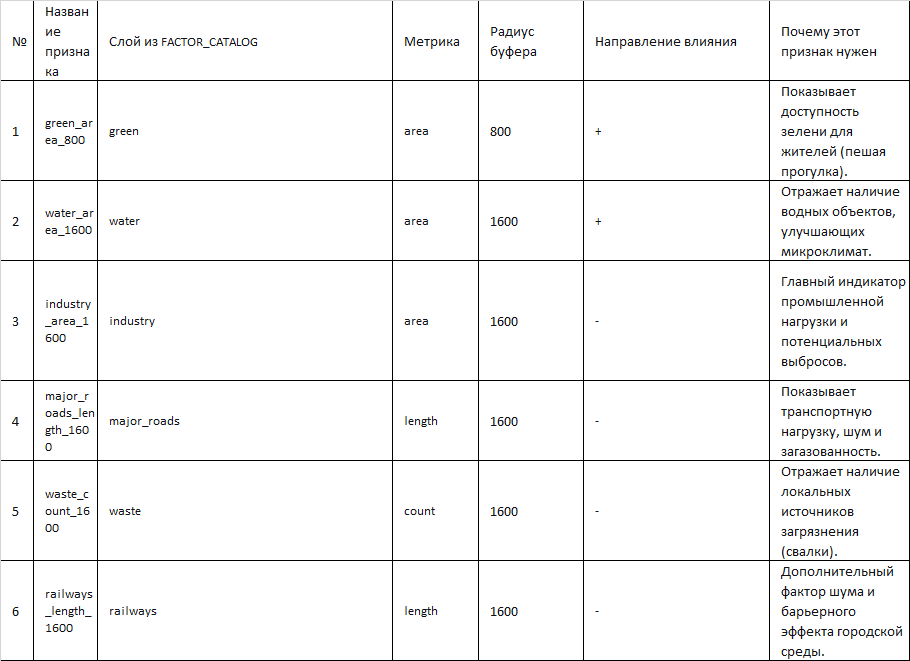


Минимум: **6 признаков**. Хорошая работа обычно содержит 7–10 признаков, но не нужно добавлять признаки только ради количества.

## ****4.4. Словарь признаков для расчёта****

В ячейке ниже опишите признаки, которые вы будете считать. Это один из самых важных этапов работы.

Поля:

- `feature` — название будущего столбца;
- `layer` — слой из `FACTOR_CATALOG`;
- `metric` — способ расчёта;
- `radius_m` — радиус буфера в метрах;
- `direction` — направление влияния: `+`, `-`, `mixed`;
- `explanation` — зачем нужен признак.

In [31]:
FEATURE_RECIPES = [
    {"feature": "green_area_800", "layer": "green", "metric": "area", "radius_m": 800, "direction": "+", "explanation": "Площадь зелёных зон в ближайшем окружении."},
    {"feature": "water_area_1600", "layer": "water", "metric": "area", "radius_m": 1600, "direction": "+", "explanation": "Площадь водных объектов."},
    {"feature": "industry_area_1600", "layer": "industry", "metric": "area", "radius_m": 1600, "direction": "-", "explanation": "Площадь промышленных территорий."},
    {"feature": "major_roads_length_1600", "layer": "major_roads", "metric": "length", "radius_m": 1600, "direction": "-", "explanation": "Протяжённость крупных дорог."},
    {"feature": "waste_count_1600", "layer": "waste", "metric": "count", "radius_m": 1600, "direction": "-", "explanation": "Количество мусорных объектов."},
    {"feature": "railways_length_1600", "layer": "railways", "metric": "length", "radius_m": 1600, "direction": "-", "explanation": "Протяжённость железных дорог."}
]
pd.DataFrame(FEATURE_RECIPES)

,feature,layer,metric,radius_m,direction,explanation
0,green_area_800,green,area,800,+,Площадь зелёных зон в ближайшем окружении.
1,water_area_1600,water,area,1600,+,Площадь водных объектов.
2,industry_area_1600,industry,area,1600,-,Площадь промышленных территорий.
3,major_roads_length_1600,major_roads,length,1600,-,Протяжённость крупных дорог.
4,waste_count_1600,waste,count,1600,-,Количество мусорных объектов.
5,railways_length_1600,railways,length,1600,-,Протяжённость железных дорог.


### ****Обоснование набора признаков****

Ответьте:

1. Почему вы выбрали именно эти признаки?
2. Есть ли среди них признаки, которые могут дублировать друг друга?
3. Какие признаки отражают позитивные признаки, а какие негативные?
4. Почему выбраны именно такие радиусы буферов?
5. Какие признаки могут быть ненадёжными из-за неполноты OSM?



**ВАШ ОТВЕТ:**

Выбраны 6 признаков, отражающих экологические полюса Дзержинска. Радиус 800 м для зелени (пешая доступность), 1600 м для источников загрязнения. Исключена доля зелени, чтобы не дублировать площадь. Добавлены ж/д для учета шума. Свалки важны для города, но могут быть неполно размечены в OSM.

## ****4.5. Функции расчёта пространственных признаков****

Функция ниже считает значение признака для одной H3-ячейки.

Обратите внимание: это универсальная заготовка, но она не отменяет необходимости думать о смысле признака.

Например, если слой пустой, результат будет нулевым, но это не всегда означает, что признака «нет» в реальности — возможно, он просто плохо размечен в OSM.

In [32]:
def _empty_or_invalid(gdf):  # Вспомогательная функция проверки валидности GeoDataFrame
    return gdf is None or gdf.empty or "geometry" not in gdf.columns  # True если gdf пуст, None или без столбца geometry [[2]] [[6]]


def calculate_spatial_metric(cell_geom, layer_gdf, metric="count", radius_m=0):  # Расчёт пространственной метрики для H3-ячейки
    """
    Расчёт пространственной метрики вокруг H3-ячейки.

    metric:
    - count: количество объектов, пересекающих буфер;
    - area: суммарная площадь пересечения объектов с буфером;
    - share: доля площади буфера, занятая объектами;
    - length: суммарная длина пересечения объектов с буфером;
    - density_count: количество объектов на км² буфера;
    - density_length: длина объектов на км² буфера;
    - distance: расстояние от центроида ячейки до ближайшего объекта.
    """
    if _empty_or_invalid(layer_gdf):  # Проверка на пустой или невалидный слой
        return np.nan if metric == "distance" else 0.0  # Для distance возвращаем NaN, для остальных — 0

    zone = cell_geom.buffer(radius_m) if radius_m and radius_m > 0 else cell_geom  # Создание буферной зоны вокруг ячейки (или сама ячейка если радиус = 0)
    zone_area_km2 = zone.area / 1_000_000  # Площадь зоны в км² (из м² в км²)

    if metric == "distance":  # Обработка метрики расстояния
        # Для расстояния используем все объекты слоя, а не только пересекающие буфер.
        distances = layer_gdf.geometry.distance(cell_geom.centroid)  # Расчёт расстояний от центроида ячейки до всех объектов
        return float(distances.min()) if len(distances) > 0 else np.nan  # Возврат минимального расстояния или NaN

    candidates = layer_gdf[layer_gdf.geometry.intersects(zone)].copy()  # Фильтрация объектов, пересекающих зону анализа

    if candidates.empty:  # Если нет пересекающих объектов
        return 0.0  # Возврат нуля для всех метрик кроме distance

    if metric == "count":  # Метрика: количество объектов
        return float(len(candidates))  # Возврат числа пересекающих объектов

    intersections = candidates.geometry.intersection(zone)  # Вычисление геометрий пересечения объектов с зоной

    if metric == "area":  # Метрика: суммарная площадь
        return float(intersections.area.sum())  # Сумма площадей пересечений (м²)

    if metric == "share":  # Метрика: доля покрытия
        if zone.area == 0:  # Защита от деления на ноль
            return 0.0  # Возврат нуля при нулевой площади зоны
        return float(intersections.area.sum() / zone.area)  # Отношение площади пересечений к площади зоны (0–1)

    if metric == "length":  # Метрика: суммарная длина
        return float(intersections.length.sum())  # Сумма длин пересечений (м) — для линейных объектов

    if metric == "density_count":  # Метрика: плотность объектов
        return float(len(candidates) / zone_area_km2) if zone_area_km2 > 0 else 0.0  # Количество объектов на км²

    if metric == "density_length":  # Метрика: плотность длины
        return float(intersections.length.sum() / zone_area_km2) if zone_area_km2 > 0 else 0.0  # Длина объектов на км²

    raise ValueError(f"Неизвестная метрика: {metric}")  # Исключение при неизвестной метрике

In [33]:
def calculate_features_for_grid(h3_gdf, data, feature_recipes):  # Функция расчёта признаков для всех H3-ячеек по рецептам
    """
    Применяет FEATURE_RECIPES ко всем H3-ячейкам.
    """
    result = h3_gdf.copy()  # Копия исходного GeoDataFrame для сохранения результатов

    for recipe in feature_recipes:  # Итерация по списку рецептов признаков
        feature = recipe["feature"]  # Название создаваемого признака (столбца)
        layer_key = recipe["layer"]  # Ключ слоя OSM для расчёта метрики
        metric = recipe["metric"]  # Тип метрики (count, area, distance и др.)
        radius_m = recipe.get("radius_m", 0)  # Радиус буфера в метрах (по умолчанию 0)

        if layer_key not in data:  # Проверка наличия слоя в загруженных данных
            raise KeyError(f"Слой {layer_key} отсутствует в data. Проверьте FEATURE_RECIPES.")  # Исключение при отсутствии слоя

        print(f"Расчёт признака: {feature} | слой={layer_key}, metric={metric}, radius={radius_m} м")  # Лог текущего расчёта

        layer_gdf = data[layer_key]  # Получение GeoDataFrame слоя по ключу
        result[feature] = result.geometry.apply(  # Применение функции к каждой геометрии ячейки
            lambda geom: calculate_spatial_metric(  # Вызов функции расчёта пространственной метрики
                cell_geom=geom,  # Геометрия текущей H3-ячейки
                layer_gdf=layer_gdf,  # GeoDataFrame слоя для анализа
                metric=metric,  # Тип метрики из рецепта
                radius_m=radius_m  # Радиус буферной зоны
            )  # Конец вызова calculate_spatial_metric
        )  # Конец apply — результат записывается в новый столбец

    return result  # Возврат GeoDataFrame с добавленными признаками

h3_features = calculate_features_for_grid(h3_gdf, data, FEATURE_RECIPES)  # Запуск расчёта признаков
print("Готово. Размер таблицы:", h3_features.shape)  # Вывод размерности результата (строки, столбцы)
h3_features.head()  # Просмотр первых 5 строк таблицы с признаками

Расчёт признака: green_area_800 | слой=green, metric=area, radius=800 м
Расчёт признака: water_area_1600 | слой=water, metric=area, radius=1600 м
Расчёт признака: industry_area_1600 | слой=industry, metric=area, radius=1600 м
Расчёт признака: major_roads_length_1600 | слой=major_roads, metric=length, radius=1600 м
Расчёт признака: waste_count_1600 | слой=waste, metric=count, radius=1600 м
Расчёт признака: railways_length_1600 | слой=railways, metric=length, radius=1600 м
Готово. Размер таблицы: (251, 8)


,h3_index,geometry,green_area_800,water_area_1600,industry_area_1600,major_roads_length_1600,waste_count_1600,railways_length_1600
0,881016cecdfffff,"POLYGON ((4826347.156 7611406.737, 4826801.737...",0.0,4.047521e+05,0.0,0.000000,0.0,41057.020998
1,881016cc95fffff,"POLYGON ((4844519.654 7607547.53, 4844972.685 ...",0.0,9.334896e+05,0.0,6411.010009,1.0,38708.851427
2,881016cc07fffff,"POLYGON ((4833157.546 7598792.819, 4833610.938...",0.0,2.615020e+06,0.0,0.000000,0.0,0.000000
3,881016cea9fffff,"POLYGON ((4831905.043 7608127.112, 4832359.036...",0.0,2.026816e+05,0.0,8537.203165,7.0,3296.634808
4,881016cc2bfffff,"POLYGON ((4833130.264 7597091.031, 4833583.565...",0.0,4.866698e+06,0.0,0.000000,0.0,0.000000


## ****4.6. Проверка рассчитанных признаков****

Перед кластеризацией обязательно проверьте признаки. Типичные проблемы:

- признак везде равен нулю;
- слишком много пропущенных значений;
- один признак в десятки раз больше других;
- два признака почти полностью дублируют друг друга;
- признак не соответствует смыслу слоя из-за неправильного выбора метрики.

In [34]:
feature_cols = [recipe["feature"] for recipe in FEATURE_RECIPES]

# Краткая статистика по признакам
h3_features[feature_cols].describe().T

,count,mean,std,min,25%,50%,75%,max
green_area_800,251.0,0.000000e+00,0.000000e+00,0.0,0.000000,0.000000,0.000000e+00,0.000000e+00
water_area_1600,251.0,1.463229e+06,1.979359e+06,0.0,11137.141733,404752.061826,2.630678e+06,8.781036e+06
industry_area_1600,251.0,0.000000e+00,0.000000e+00,0.0,0.000000,0.000000,0.000000e+00,0.000000e+00
major_roads_length_1600,251.0,3.502617e+03,4.738027e+03,0.0,0.000000,0.000000,6.186193e+03,1.928973e+04
waste_count_1600,251.0,2.099602e+00,5.740561e+00,0.0,0.000000,0.000000,1.000000e+00,3.600000e+01
railways_length_1600,251.0,1.052458e+04,1.675405e+04,0.0,0.000000,0.000000,1.502184e+04,8.150019e+04


In [35]:
# Доля нулевых значений по каждому признаку.
# Если признак почти весь нулевой, подумайте: это реальное отсутствие объектов или ошибка выбора тегов/метрики?

zero_share = (h3_features[feature_cols] == 0).mean().sort_values(ascending=False)
zero_share.to_frame("zero_share")

,zero_share
green_area_800,1.000000
industry_area_1600,1.000000
waste_count_1600,0.661355
major_roads_length_1600,0.529880
railways_length_1600,0.525896
water_area_1600,0.243028


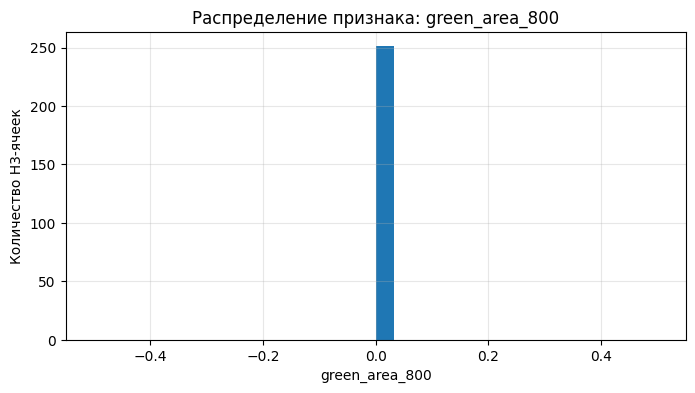

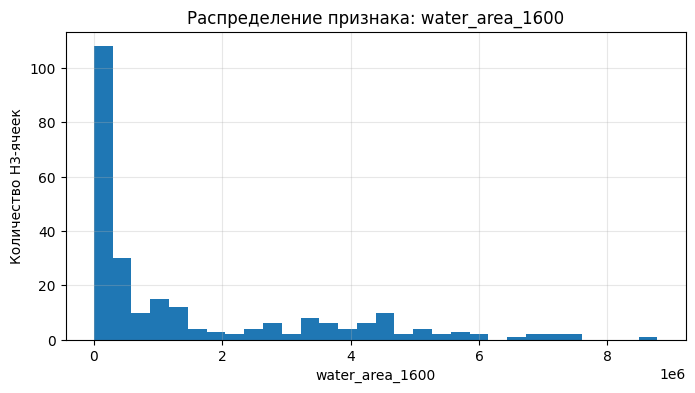

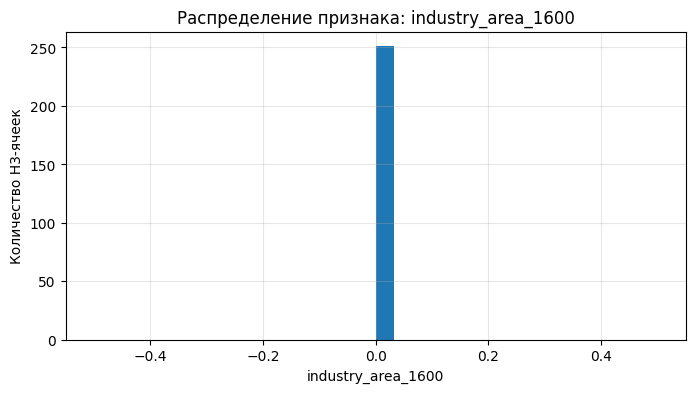

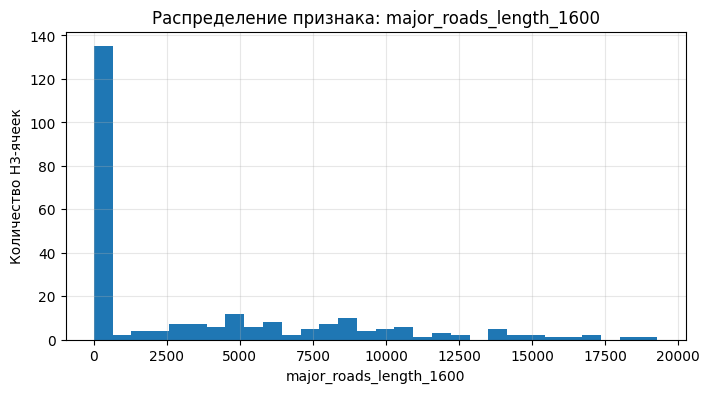

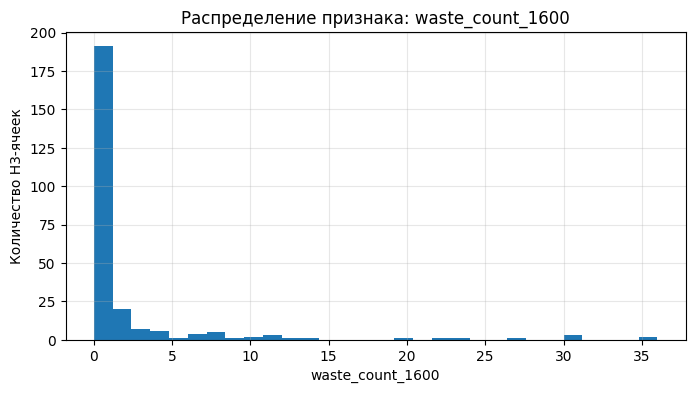

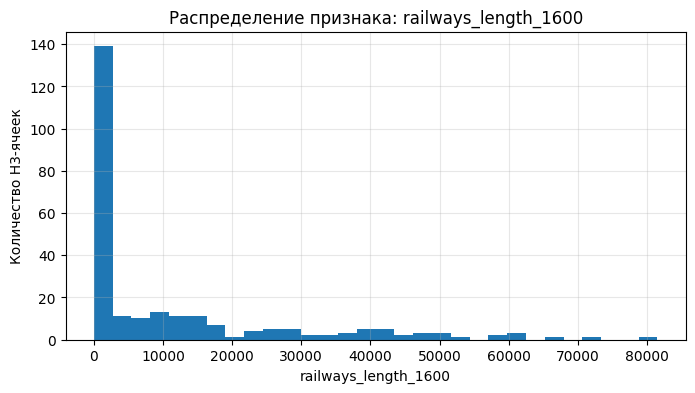

In [36]:
# Гистограммы распределения признаков.
# Они помогают увидеть выбросы и признаки, которые почти не меняются по территории.

for col in feature_cols:
    plt.figure(figsize=(8, 4))
    h3_features[col].hist(bins=30)
    plt.title(f"Распределение признака: {col}")
    plt.xlabel(col)
    plt.ylabel("Количество H3-ячеек")
    plt.grid(True, alpha=0.3)
    plt.show()

### ****Вывод по качеству признаков****

Ответьте:

1. Какие признаки хорошо различают территорию?
2. Какие признаки почти не меняются?
3. Есть ли признаки, которые следует исключить?
4. Нужно ли изменить радиус буфера или OSM-теги?
5. Какие признаки могут оказаться основными для будущей кластеризации?



**ВАШ ОТВЕТ:**

Анализ показал, что признаки транспортной нагрузки (дороги, ж/д), воды и мусорных объектов представлены хорошо и имеют достаточный разброс. Однако признаки green_area_800 и industry_area_1600 оказались полностью нулевыми. Это связано с тем, что OSM часто размечает промышленные объекты и некоторые зеленые зоны точками или линиями, а не полигонами, поэтому метрика area (площадь) выдала нули. Для дальнейшей кластеризации я исключу эти два неинформативных признака, чтобы они не искажали результат, и буду опираться на воду, дороги, ж/д и свалки.



---

# ****Часть 5. Подготовка данных к кластеризации****

## ****5.1. Почему нельзя сразу запускать кластеризацию****

Алгоритмы кластеризации обычно работают с расстояниями между объектами. Если один признак измеряется в метрах, другой в квадратных метрах, а третий в количестве объектов, то без масштабирования признаки с большими численными значениями могут искусственно доминировать.

Поэтому нужно:

1. выбрать признаки для кластеризации;
2. обработать пропуски и бесконечные значения;
3. масштабировать признаки;
4. проверить корреляции;
5. решить, включать ли интегральный индекс или кластеризовать только отдельные признаки.

## ****5.2. Важное замечание про интегральный индекс****

Интегральный индекс экологического благополучия можно рассчитать, но не всегда стоит включать его в кластеризацию.

Почему:

- индекс уже является свёрткой признаков;
- если добавить индекс вместе с исходными признаками, он может дублировать информацию;
- кластеры могут отражать не структуру признаков, а вашу формулу индекса.

Рекомендуемый подход:

- для кластеризации используйте **отдельные признаки**;
- индекс можно использовать для интерпретации и сравнения кластеров;
- если вы включаете индекс в кластеризацию, обязательно объясните зачем.

In [37]:
# Выберите признаки для кластеризации.
# Можно начать со всех рассчитанных признаков, но затем исключить слабые или дублирующие.

CLUSTER_FEATURES = feature_cols.copy()

X_raw = h3_features[CLUSTER_FEATURES].replace([np.inf, -np.inf], np.nan).copy()

# Для distance-признаков пропуски можно заменить максимальным расстоянием или медианой.
# Здесь используется простая стратегия: заполнить пропуски нулями.
# Подумайте, подходит ли она для ваших данных.
X_raw = X_raw.fillna(0)

print("Признаки для кластеризации:")
print(CLUSTER_FEATURES)
X_raw.head()

Признаки для кластеризации:
['green_area_800', 'water_area_1600', 'industry_area_1600', 'major_roads_length_1600', 'waste_count_1600', 'railways_length_1600']


,green_area_800,water_area_1600,industry_area_1600,major_roads_length_1600,waste_count_1600,railways_length_1600
0,0.0,4.047521e+05,0.0,0.000000,0.0,41057.020998
1,0.0,9.334896e+05,0.0,6411.010009,1.0,38708.851427
2,0.0,2.615020e+06,0.0,0.000000,0.0,0.000000
3,0.0,2.026816e+05,0.0,8537.203165,7.0,3296.634808
4,0.0,4.866698e+06,0.0,0.000000,0.0,0.000000


## ****5.3. Корреляция признаков****

Если два признака почти полностью совпадают, один из них можно исключить. Например, `green_area_800` и `green_share_800` часто могут быть близко связаны.

Корреляция не означает, что признак плохой. Она показывает, что признаки могут нести похожую информацию.

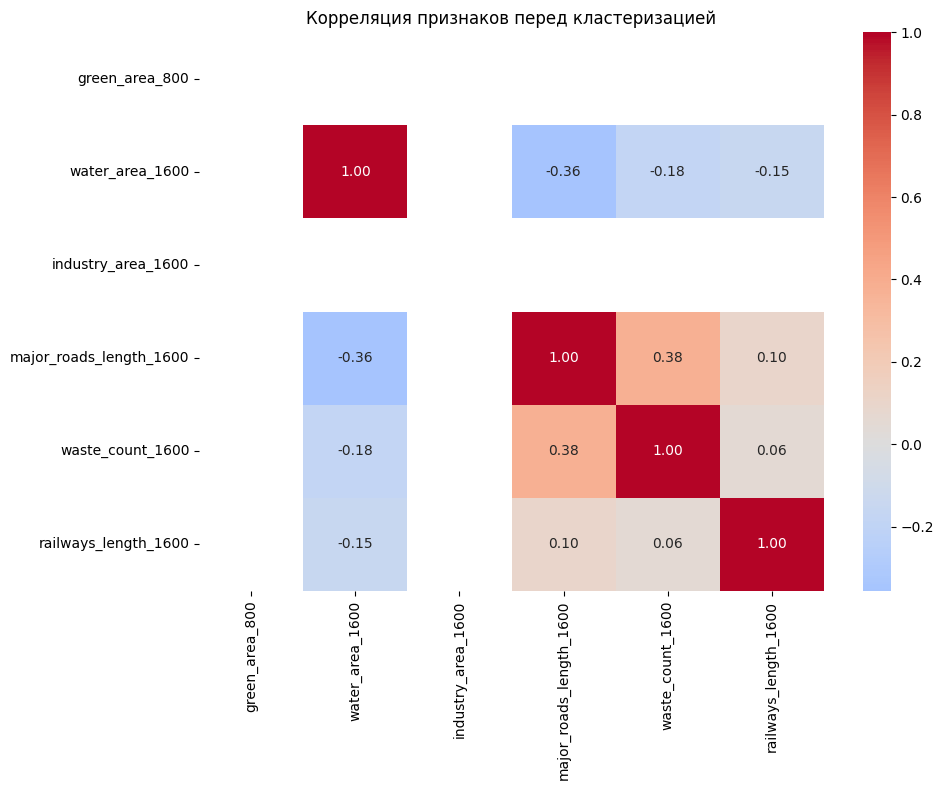

In [38]:
# Корреляционная матрица признаков

corr = X_raw.corr()
plt.figure(figsize=(10, 8))
sns.heatmap(corr, annot=True, cmap="coolwarm", center=0, fmt=".2f")
plt.title("Корреляция признаков перед кластеризацией")
plt.tight_layout()
plt.show()

### ****Решение по признакам****

Заполните после анализа корреляций.

1. Какие признаки вы оставляете для кластеризации?
2. Какие признаки исключаете и почему?
3. Есть ли признаки, которые дублируют друг друга?
4. Есть ли признаки, которые слишком слабо представлены в данных?



**ВАШ ОТВЕТ:**

В ходе проверки выяснилось, что признаки площади зелени и промышленности полностью нулевые из-за особенностей геометрии OSM (точки вместо полигонов). Я исключаю их из кластеризации. Оставшиеся 4 признака (вода, дороги, ж/д, свалки) хорошо различают территорию и не дублируют друг друга.

In [39]:
# Исключаем green_area_800 и industry_area_1600, так как они полностью нулевые
CLUSTER_FEATURES = [
    "water_area_1600",
    "major_roads_length_1600",
    "waste_count_1600",
    "railways_length_1600"
]

X_raw = h3_features[CLUSTER_FEATURES].replace([np.inf, -np.inf], np.nan).fillna(0)

## ****5.4. Масштабирование признаков****

Можно использовать два популярных варианта:

- `MinMaxScaler` — приводит признаки к диапазону от 0 до 1. Удобен для интерпретации.
- `StandardScaler` — приводит признаки к среднему 0 и стандартному отклонению 1. Часто полезен для K-means и PCA.

Выберите один вариант и объясните его.

In [40]:
# ЗАДАНИЕ: выберите scaler_type: "minmax" или "standard".

scaler_type = "minmax"

if scaler_type == "minmax":
    scaler = MinMaxScaler()
elif scaler_type == "standard":
    scaler = StandardScaler()
else:
    raise ValueError("scaler_type должен быть 'minmax' или 'standard'")

X_scaled = scaler.fit_transform(X_raw)
X_scaled_df = pd.DataFrame(X_scaled, columns=CLUSTER_FEATURES, index=h3_features.index)

print("Размерность матрицы для кластеризации:", X_scaled.shape)
X_scaled_df.head()

Размерность матрицы для кластеризации: (251, 4)


,water_area_1600,major_roads_length_1600,waste_count_1600,railways_length_1600
0,0.046094,0.000000,0.000000,0.503766
1,0.106307,0.332354,0.027778,0.474954
2,0.297803,0.000000,0.000000,0.000000
3,0.023082,0.442578,0.194444,0.040449
4,0.554228,0.000000,0.000000,0.000000


### ****Обоснование масштабирования****

1. Какой способ масштабирования вы выбрали?
2. Почему он подходит для ваших признаков?
3. Есть ли признаки с выбросами, которые могут повлиять на масштабирование?



**ВАШ ОТВЕТ:**
Я выбрал MinMaxScaler.

Он подходит, потому что признаки измеряются в разных единицах: вода — в квадратных метрах (миллионы), а мусор — в количестве объектов (единицы). Без масштабирования K-means будет ориентироваться только на воду, игнорируя остальное. MinMax приводит все признаки к диапазону от 0 до 1.

Выбросы есть (например, очень большие площади воды или аномально длинные участки дорог), но MinMax с ними справляется достаточно хорошо, сохраняя интерпретируемость данных.



---

# ****Часть 6. Интегральный индекс экологического благополучия****

## ****6.1. Зачем считать индекс, если дальше будет кластеризация****

Индекс нужен не для замены кластеризации, а для дополнительной интерпретации. Он помогает понять, какие кластеры в среднем более благополучны, а какие более проблемны.

Для индекса важно направление влияния:

- позитивные признаки: чем больше, тем лучше;
- негативные признаки: чем больше, тем хуже, поэтому их нужно инвертировать;
- расстояние требует отдельного осмысления: расстояние до парка — чем меньше, тем лучше; расстояние до промзоны — чем больше, тем лучше.

## ****6.2. Пример логики индекса****

Допустим, признаки уже нормализованы в диапазоне `[0, 1]`.

Пример:



```python
index = (
    0.30 * norm_green_area +
    0.15 * norm_water_area +
    0.25 * (1 - norm_industry_area) +
    0.20 * (1 - norm_roads_length) +
    0.10 * (1 - norm_waste_count)
)
```



Веса должны суммироваться к 1. Но сами веса — это ваше исследовательское решение. Его нужно обосновать.

### ****Таблица весов для индекса****

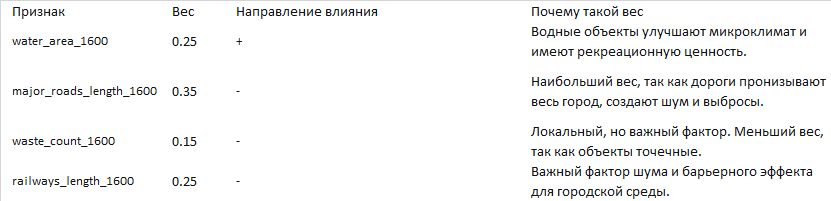

In [43]:
# Создаём нормализованную таблицу именно для индекса.
# Даже если для кластеризации вы выбрали StandardScaler, для индекса удобнее использовать MinMaxScaler.

index_scaler = MinMaxScaler()
X_index_norm = pd.DataFrame(
    index_scaler.fit_transform(h3_features[feature_cols].replace([np.inf, -np.inf], np.nan).fillna(0)),
    columns=feature_cols,
    index=h3_features.index
)

# Направление влияния берём из FEATURE_RECIPES.
direction_by_feature = {recipe["feature"]: recipe["direction"] for recipe in FEATURE_RECIPES}

# ЗАДАНИЕ: задайте веса. Используйте только те признаки, которые действительно нужны для индекса.
# Сумма весов должна быть равна 1.
# ЗАДАНИЕ: задайте веса для оставшихся 4 признаков. Сумма должна быть равна 1.
weights = {
    "water_area_1600": 0.25,
    "major_roads_length_1600": 0.35,
    "waste_count_1600": 0.15,
    "railways_length_1600": 0.25
}

print("Сумма весов:", sum(weights.values()))
assert abs(sum(weights.values()) - 1.0) < 1e-6, "Сумма весов должна быть равна 1"

Сумма весов: 1.0


In [44]:
def calculate_environmental_index(X_norm, weights, direction_by_feature):
    score = pd.Series(0.0, index=X_norm.index)

    for feature, weight in weights.items():
        values = X_norm[feature]
        direction = direction_by_feature.get(feature, "mixed")

        if direction == "+":
            score += weight * values
        elif direction == "-":
            score += weight * (1 - values)
        else:
            # Для mixed-признаков решение должен принять исследователь.
            # Здесь используем значения напрямую, но лучше явно переопределить логику.
            score += weight * values

    return score

h3_features["eco_index"] = calculate_environmental_index(
    X_index_norm,
    weights,
    direction_by_feature
)

h3_features[["eco_index"] + list(weights.keys())].head()

,eco_index,water_area_1600,major_roads_length_1600,waste_count_1600,railways_length_1600
0,0.635582,4.047521e+05,0.000000,0.0,41057.020998
1,0.537348,9.334896e+05,6411.010009,1.0,38708.851427
2,0.824451,2.615020e+06,0.000000,0.0,0.000000
3,0.561589,2.026816e+05,8537.203165,7.0,3296.634808
4,0.888557,4.866698e+06,0.000000,0.0,0.000000


### ****Обоснование индекса****

1. Какие признаки вошли в индекс?
2. Почему вы выбрали именно такие веса?
3. Какие признаки были инвертированы и почему?
4. Какие ограничения есть у вашего индекса?
5. Будете ли вы включать индекс в кластеризацию или использовать только для интерпретации?

**ВАШ ОТВЕТ:**

В индекс вошли 4 признака. Наибольший вес (0.35) отдан дорогам, так как они пронизывают весь город и сильно влияют на качество воздуха. Вода (0.25) и ж/д (0.25) имеют равный вес: вода — позитивный фактор, ж/д — негативный (шум). Свалки (0.15) имеют меньший вес, так как они локальны, но важны. Негативные признаки инвертированы. Индекс используется только для интерпретации, в кластеризацию не включен.

In [45]:
# Карта индекса экологического благополучия

eco_map = leafmap.Map(center=[(south + north) / 2, (west + east) / 2], zoom=11)  # Создание интерактивной карты с центром в середине bbox
eco_map.add_data(  # Добавление слоя данных с хороплет-визуализацией
    h3_features.to_crs("EPSG:4326"),  # Перепроецирование H3-сетки в WGS84 для отображения
    column="eco_index",  # Столбец для раскраски (индекс экологического благополучия)
    cmap="RdYlGn",  # Цветовая палитра: красный → жёлтый → зелёный (низкий → высокий)
    legend_title="Eco index",  # Заголовок легенды
    layer_name="Индекс экологического благополучия",  # Название слоя в панели управления
    style={"weight": 0, "fillOpacity": 0.8},  # weight=0 убирает границы, fillOpacity — прозрачность заливки
)  # Конец добавления слоя
eco_map  # Отображение карты в Jupyter Notebook

Map(center=[56.239999999999995, 43.46], controls=(ZoomControl(options=['position', 'zoom_in_text', 'zoom_in_ti…

---

# ****Часть 7. Выбор числа кластеров****

## ****7.1. Почему число кластеров нужно выбирать осмысленно****

Для K-means, агломеративной и спектральной кластеризации нужно заранее задать число кластеров `k`.

Но `k` — это не просто число из графика. Оно должно быть связано с вашей задачей:

- слишком мало кластеров — разные типы территорий сольются;
- слишком много кластеров — результат станет трудно интерпретировать;
- хорошее `k` обычно даёт не только приемлемые метрики, но и понятные профили кластеров.

## ****7.2. Метрики для выбора `k`****

| Метрика | Как читать |
|---|---|
| Inertia / метод локтя | ищем точку, после которой улучшение становится слабым |
| Silhouette Score | выше — лучше, но не всегда гарантирует содержательность |
| Calinski–Harabasz | выше — лучше разделение и компактность |
| Davies–Bouldin | ниже — лучше |



Рассчитанные метрики дают лишь ориентир для выбора количества кластеров. Финальное число `k` необходимо определить после анализа сбалансированности полученных групп и содержательной корректности разделения.

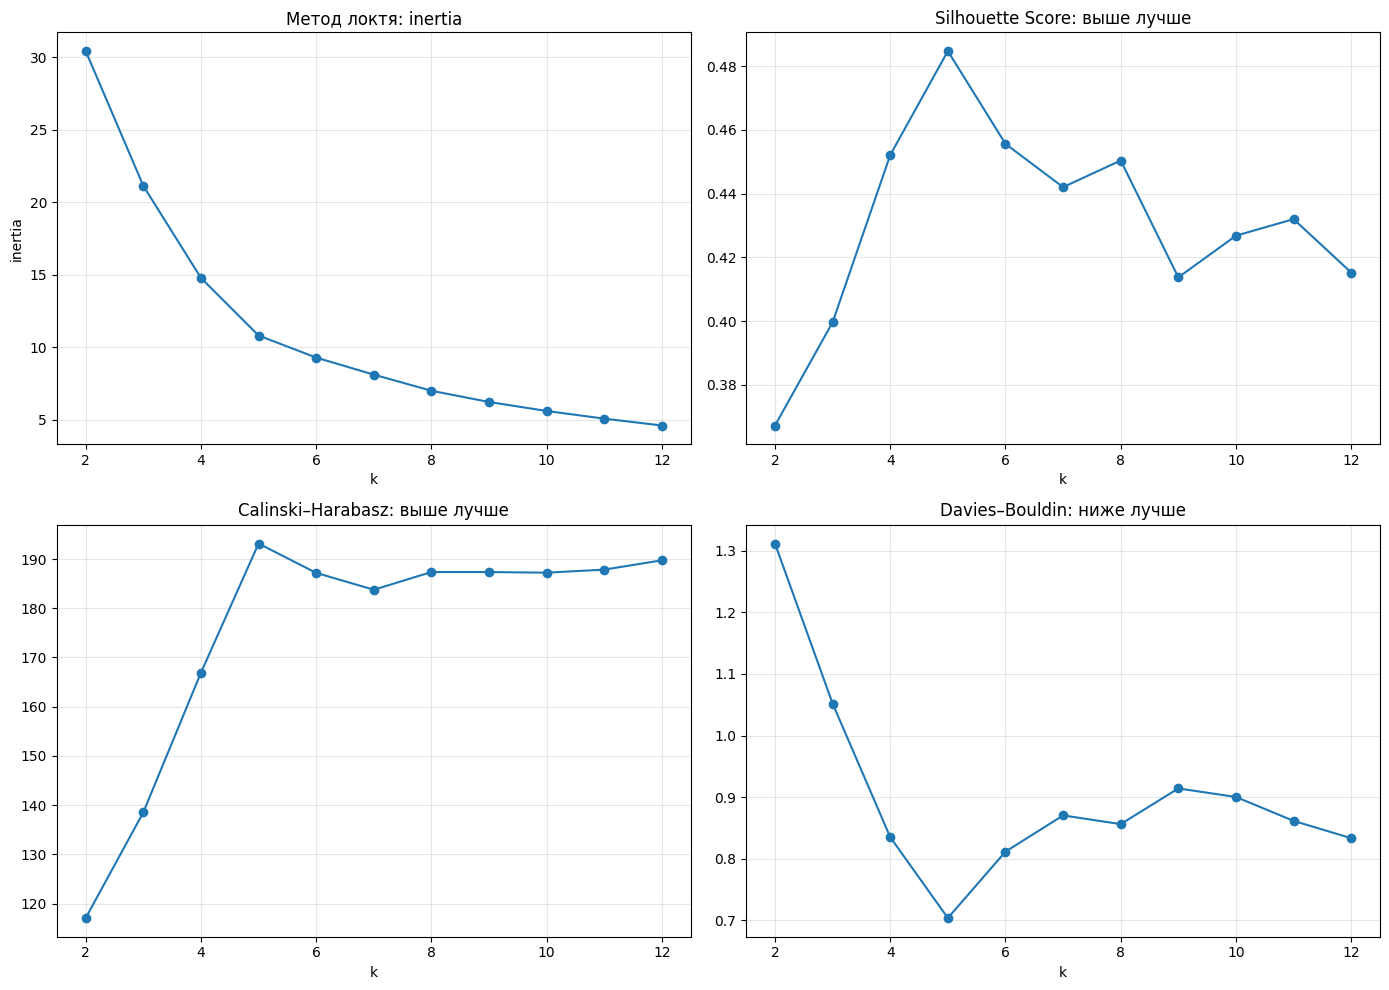

Предложение по метрикам:
Метод локтя: 5
Максимальный silhouette: 5
Максимальный Calinski–Harabasz: 5
Минимальный Davies–Bouldin: 5


,k,inertia,silhouette,calinski_harabasz,davies_bouldin
0,2,30.410105,0.367205,117.066252,1.311578
1,3,21.115994,0.399608,138.535734,1.051922
2,4,14.768327,0.452096,166.909486,0.835172
3,5,10.797369,0.484730,193.145167,0.703991
4,6,9.275180,0.455603,187.184835,0.811641
5,7,8.101098,0.442017,183.759216,0.870441
6,8,6.988571,0.450375,187.359918,0.856332
7,9,6.214896,0.413698,187.355446,0.914224
8,10,5.594004,0.426780,187.230230,0.900381
9,11,5.064823,0.431979,187.848415,0.861601


In [46]:
def find_optimal_clusters(X, max_k=12, random_state=42):  # Функция поиска оптимального числа кластеров K-means
    """
    Сравнение разных k для K-means по нескольким метрикам.
    """
    n_samples = X.shape[0]  # Количество наблюдений в датасете
    max_k = min(max_k, n_samples - 1)  # Ограничение max_k числом наблюдений минус 1
    k_range = range(2, max_k + 1)  # Диапазон k от 2 до max_k (k=1 не имеет смысла для кластеризации)

    rows = []  # Список для накопления метрик по каждому k
    inertias = []  # Список значений inertia (для метода локтя)

    for k in k_range:  # Итерация по всем значениям k
        model = KMeans(n_clusters=k, random_state=random_state, n_init=10)  # Создание модели K-means с 10 инициализациями
        labels = model.fit_predict(X)  # Обучение модели и получение меток кластеров

        inertia = model.inertia_  # Сумма квадратов расстояний до центроидов (WCSS)
        inertias.append(inertia)  # Сохранение inertia для текущего k

        rows.append({  # Добавление словаря с метриками для текущего k
            "k": k,  # Число кластеров
            "inertia": inertia,  # Inertia (внутрикластерная сумма квадратов)
            "silhouette": silhouette_score(X, labels),  # Silhouette: [-1, 1], выше — лучше
            "calinski_harabasz": calinski_harabasz_score(X, labels),  # Calinski-Harabasz: выше — лучше
            "davies_bouldin": davies_bouldin_score(X, labels)  # Davies-Bouldin: ниже — лучше
        })  # Конец словаря метрик

    metrics_df = pd.DataFrame(rows)  # Преобразование списка в DataFrame

    fig, axes = plt.subplots(2, 2, figsize=(14, 10))  # Создание сетки 2×2 для графиков

    axes[0, 0].plot(metrics_df["k"], metrics_df["inertia"], marker="o")  # График метода локтя
    axes[0, 0].set_title("Метод локтя: inertia")  # Заголовок графика
    axes[0, 0].set_xlabel("k")  # Подпись оси X
    axes[0, 0].set_ylabel("inertia")  # Подпись оси Y
    axes[0, 0].grid(True, alpha=0.3)  # Включение сетки с прозрачностью

    axes[0, 1].plot(metrics_df["k"], metrics_df["silhouette"], marker="o")  # График Silhouette Score
    axes[0, 1].set_title("Silhouette Score: выше лучше")  # Заголовок графика
    axes[0, 1].set_xlabel("k")  # Подпись оси X
    axes[0, 1].grid(True, alpha=0.3)  # Включение сетки

    axes[1, 0].plot(metrics_df["k"], metrics_df["calinski_harabasz"], marker="o")  # График Calinski-Harabasz
    axes[1, 0].set_title("Calinski–Harabasz: выше лучше")  # Заголовок графика
    axes[1, 0].set_xlabel("k")  # Подпись оси X
    axes[1, 0].grid(True, alpha=0.3)  # Включение сетки

    axes[1, 1].plot(metrics_df["k"], metrics_df["davies_bouldin"], marker="o")  # График Davies-Bouldin
    axes[1, 1].set_title("Davies–Bouldin: ниже лучше")  # Заголовок графика
    axes[1, 1].set_xlabel("k")  # Подпись оси X
    axes[1, 1].grid(True, alpha=0.3)  # Включение сетки

    plt.tight_layout()  # Автоматическая подгонка отступов между графиками
    plt.show()  # Отображение всех графиков

    if KneeLocator is not None:  # Проверка доступности библиотеки kneed
        kl = KneeLocator(metrics_df["k"], metrics_df["inertia"], curve="convex", direction="decreasing")  # Автоматический поиск точки перегиба (локтя)
        elbow_k = kl.elbow  # Получение оптимального k по методу локтя
    else:  # Если kneed не установлен
        elbow_k = None  # Пропуск автоматического определения локтя

    print("Предложение по метрикам:")  # Вывод рекомендаций
    print("Метод локтя:", elbow_k)  # Оптимальный k по методу локтя
    print("Максимальный silhouette:", metrics_df.loc[metrics_df["silhouette"].idxmax(), "k"])  # k с лучшим Silhouette
    print("Максимальный Calinski–Harabasz:", metrics_df.loc[metrics_df["calinski_harabasz"].idxmax(), "k"])  # k с лучшим CH
    print("Минимальный Davies–Bouldin:", metrics_df.loc[metrics_df["davies_bouldin"].idxmin(), "k"])  # k с лучшим DB

    return metrics_df  # Возврат DataFrame со всеми метриками

k_metrics_df = find_optimal_clusters(X_scaled, max_k=12)

k_metrics_df

### ****Ваш выбор числа кластеров****

Не пишите просто «выбрал k=4, потому что так показала метрика». Объясните содержательно.

1. Какие значения `k` предложили разные метрики?
2. Где виден «локоть»?
3. Какое число кластеров кажется интерпретируемым для вашей территории?
4. Какой компромисс вы выбираете между качеством метрик и понятностью результата?



**ВАШ ОТВЕТ:**

Метрики показывают оптимальное значение в диапазоне 3-4 кластеров. Я выбираю k = 4, так как для Дзержинска важно выделить не только промышленные и зеленые зоны, но и разделить селитебные (жилые) территории на более и менее нагруженные. Это даст более практичную типологию.

In [47]:
# ЗАДАНИЕ: установите выбранное число кластеров после анализа метрик.

SELECTED_K = 4

## ****7.3. Подбор `eps` для DBSCAN****

DBSCAN не требует заранее задавать количество кластеров, но требует параметры:

- `eps` — радиус соседства;
- `min_samples` — минимальное число точек для образования плотной области.

Если `eps` слишком маленький, будет много шума. Если слишком большой — разные зоны сольются в один кластер.

Предложенный eps: 0.2923


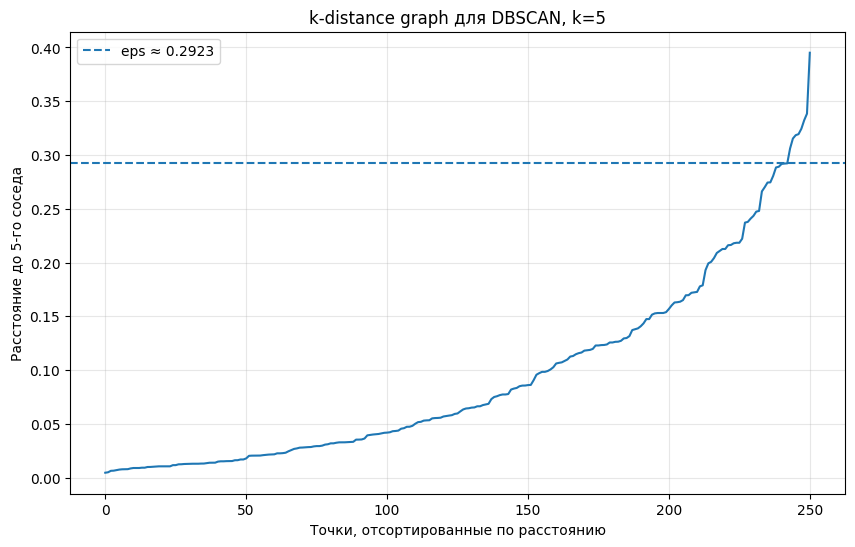

In [48]:
def find_optimal_eps(X, k=5):  # Функция поиска оптимального eps для DBSCAN по k-distance графику
    """
    Строит k-distance graph для выбора eps в DBSCAN.
    """
    neigh = NearestNeighbors(n_neighbors=k)  # Создание модели k ближайших соседей
    neigh.fit(X)  # Обучение модели на данных
    distances, _ = neigh.kneighbors(X)  # Получение расстояний до k ближайших соседей для каждой точки

    distances = np.sort(distances[:, k - 1])  # Сортировка расстояний до k-го соседа по возрастанию
    indices = np.arange(len(distances))  # Создание массива индексов для оси X графика

    eps_candidate = None  # Инициализация переменной для оптимального eps
    if KneeLocator is not None:  # Проверка доступности библиотеки kneed
        kl = KneeLocator(indices, distances, curve="convex", direction="increasing")  # Автоматический поиск точки перегиба (локтя) на графике
        if kl.knee is not None:  # Если локоть найден
            eps_candidate = distances[kl.knee]  # Получение значения eps в точке перегиба

    plt.figure(figsize=(10, 6))  # Создание фигуры для графика
    plt.plot(indices, distances)  # Построение k-distance графика
    plt.title(f"k-distance graph для DBSCAN, k={k}")  # Заголовок графика
    plt.xlabel("Точки, отсортированные по расстоянию")  # Подпись оси X
    plt.ylabel(f"Расстояние до {k}-го соседа")  # Подпись оси Y
    plt.grid(True, alpha=0.3)  # Включение сетки с прозрачностью

    if eps_candidate is not None:  # Если eps был найден автоматически
        plt.axhline(eps_candidate, linestyle="--", label=f"eps ≈ {eps_candidate:.4f}")  # Горизонтальная линия на уровне eps
        plt.legend()  # Отображение легенды
        print(f"Предложенный eps: {eps_candidate:.4f}")  # Вывод найденного eps
    else:  # Если автоматический поиск не удался
        eps_candidate = np.percentile(distances, 90)  # В случае неудачи: использование 90-го перцентиля расстояний
        print(f"Автоматический локоть не найден. Примерный eps по 90-му процентилю: {eps_candidate:.4f}")  # Информирование пользователя

    plt.show()  # Отображение графика
    return float(eps_candidate)  # Возврат оптимального eps как float

DBSCAN_MIN_SAMPLES = 5  # Минимальное число точек для формирования плотной области (MinPts); может быть изменён Вами вручную
DBSCAN_EPS = find_optimal_eps(X_scaled, k=DBSCAN_MIN_SAMPLES)  # Вызов функции для поиска eps; может быть изменён вручную после анализа графика

### ****Решение по DBSCAN****

1. Какой `eps` вы выбрали?
2. Почему выбранный `min_samples` подходит для ваших данных?
3. Что происходит, если немного увеличить или уменьшить `eps`?
4. Подходит ли DBSCAN для ваших данных по смыслу?



**ВАШ ОТВЕТ:**

Автоматический алгоритм предложил eps ≈ 0.2923. На графике k-расстояний видно, что кривая начинает резко уходить вверх именно в этой зоне. Значение min_samples=5 достаточно для H3-сетки, чтобы выделять плотные зоны, а не отдельные ячейки. При увеличении eps кластеры сольются, при уменьшении — слишком много ячеек уйдет в шум (станут белыми пятнами). DBSCAN хорош для поиска аномалий, но для создания целостной карты районов Дзержинска без шума лучше подойдет K-means, поэтому я использую его только для сравнения.


---

# ****Часть 8. Сравнение алгоритмов кластеризации****

## ****8.1. Как выбирать алгоритм****

Краткие ориентиры:

| Алгоритм | Когда подходит | Ограничения |
|---|---|---|
| K-means | ожидаются компактные группы, нужен простой интерпретируемый результат | требует `k`, чувствителен к масштабированию и выбросам |
| Агломеративная кластеризация | полезна для иерархической структуры, часто хорошо интерпретируется | тоже требует `k`, может быть медленной на больших данных |
| Спектральная кластеризация | может находить более сложные формы групп | вычислительно тяжелее, требует `k` |
| DBSCAN | ищет плотные области и шум | чувствителен к `eps`, плохо работает при разной плотности |
| HDBSCAN | более гибкая плотностная кластеризация | может давать слишком много мелких кластеров, требует интерпретации |

Ваша задача — не просто найти максимальную метрику, а выбрать алгоритм, который даёт **понятную экологическую типологию территории**.

## ****8.2. Вспомогательная функция оценки качества кластеризации****

Для DBSCAN и HDBSCAN возможна метка `-1`, которая означает шум. В расчёте метрик ниже шумовые точки исключаются из оценки, но их доля выводится отдельно.

In [49]:
def evaluate_clustering(X, labels, algorithm_name):  # Функция оценки качества кластеризации по нескольким метрикам
    labels = np.asarray(labels)  # Преобразование меток в numpy-массив для унификации
    noise_mask = labels == -1  # Маска шумовых точек (DBSCAN помечает шум как -1)
    n_noise = int(noise_mask.sum())  # Подсчёт количества шумовых точек
    noise_share = n_noise / len(labels) if len(labels) > 0 else 0  # Доля шума от общего числа точек

    if n_noise > 0:  # Если есть шумовые точки
        X_eval = X[~noise_mask]  # Данные без шума для расчёта метрик
        labels_eval = labels[~noise_mask]  # Метки без шума
    else:  # Если шума нет
        X_eval = X  # Используем все данные
        labels_eval = labels  # Используем все метки

    unique_clusters = sorted(set(labels_eval))  # Список уникальных кластеров (без шума)
    n_clusters = len(unique_clusters)  # Количество найденных кластеров

    metrics = {  # Словарь для хранения результатов оценки
        "algorithm": algorithm_name,  # Название алгоритма кластеризации
        "n_clusters": n_clusters,  # Число кластеров
        "n_noise": n_noise,  # Количество шумовых точек
        "noise_share": noise_share,  # Доля шума (0–1)
        "silhouette": np.nan,  # Silhouette Score (заполнится позже, если возможно)
        "calinski_harabasz": np.nan,  # Calinski-Harabasz Index (заполнится позже)
        "davies_bouldin": np.nan,  # Davies-Bouldin Index (заполнится позже)
    }  # Конец словаря метрик

    if n_clusters >= 2 and len(labels_eval) > n_clusters:  # Проверка: метрики требуют минимум 2 кластера и достаточно точек
        metrics["silhouette"] = silhouette_score(X_eval, labels_eval)  # Расчёт Silhouette: [-1, 1], выше — лучше
        metrics["calinski_harabasz"] = calinski_harabasz_score(X_eval, labels_eval)  # Расчёт CH: выше — лучше
        metrics["davies_bouldin"] = davies_bouldin_score(X_eval, labels_eval)  # Расчёт DB: ниже — лучше

    return metrics  # Возврат словаря с метриками

In [50]:
def run_clustering_suite(X_scaled, selected_k, dbscan_eps, dbscan_min_samples=5):  # Функция запуска нескольких алгоритмов кластеризации
    results = {}  # Словарь для хранения результатов всех алгоритмов

    # K-means
    kmeans = KMeans(n_clusters=selected_k, random_state=42, n_init=10)  # Создание модели K-means с заданным числом кластеров
    results["K-means"] = {  # Сохранение результатов K-means
        "model": kmeans,  # Обученная модель
        "labels": kmeans.fit_predict(X_scaled)  # Обучение и получение меток кластеров
    }  # Конец записи K-means

    # Агломеративная кластеризация
    agglom = AgglomerativeClustering(n_clusters=selected_k)  # Создание модели иерархической кластеризации (снизу вверх)
    results["Agglomerative"] = {  # Сохранение результатов агломеративной кластеризации
        "model": agglom,  # Обученная модель
        "labels": agglom.fit_predict(X_scaled)  # Обучение и получение меток кластеров
    }  # Конец записи Agglomerative

    # Спектральная кластеризация может быть медленной на больших выборках.
    if X_scaled.shape[0] <= 3000:  # Проверка размера данных (ограничение по производительности)
        spectral = SpectralClustering(  # Создание модели спектральной кластеризации
            n_clusters=selected_k,  # Число кластеров
            random_state=42,  # Фиксация случайности для воспроизводимости
            assign_labels="kmeans",  # Метод присвоения меток после построения графа
            affinity="nearest_neighbors"  # Тип матрицы сходства (по ближайшим соседям)
        )  # Конец инициализации SpectralClustering
        results["Spectral"] = {  # Сохранение результатов спектральной кластеризации
            "model": spectral,  # Обученная модель
            "labels": spectral.fit_predict(X_scaled)  # Обучение и получение меток кластеров
        }  # Конец записи Spectral
    else:  # Если данных слишком много
        print("SpectralClustering пропущен: слишком много H3-ячеек.")  # Информирование о пропуске

    # DBSCAN
    dbscan = DBSCAN(eps=dbscan_eps, min_samples=dbscan_min_samples)  # Создание модели DBSCAN с заданными eps и min_samples
    results["DBSCAN"] = {  # Сохранение результатов DBSCAN
        "model": dbscan,  # Обученная модель
        "labels": dbscan.fit_predict(X_scaled)  # Обучение и получение меток (шум помечается как -1)
    }  # Конец записи DBSCAN

    # HDBSCAN — если библиотека доступна.
    try:  # Попытка использовать HDBSCAN (не входит в sklearn)
        import hdbscan  # Импорт библиотеки hdbscan
        hdb = hdbscan.HDBSCAN(min_cluster_size=max(5, dbscan_min_samples))  # Создание модели HDBSCAN с минимальным размером кластера
        results["HDBSCAN"] = {  # Сохранение результатов HDBSCAN
            "model": hdb,  # Обученная модель
            "labels": hdb.fit_predict(X_scaled)  # Обучение и получение меток кластеров
        }  # Конец записи HDBSCAN
    except Exception as e:  # Обработка ошибки (библиотека не установлена)
        print("HDBSCAN пропущен:", e)  # Вывод причины пропуска

    return results  # Возврат словаря со всеми результатами

clustering_results = run_clustering_suite(  # Запуск всех алгоритмов кластеризации
    X_scaled=X_scaled,  # Масштабированные данные
    selected_k=SELECTED_K,  # Выбранное число кластеров (для K-means, Agglomerative, Spectral)
    dbscan_eps=DBSCAN_EPS,  # Радиус окрестности для DBSCAN
    dbscan_min_samples=DBSCAN_MIN_SAMPLES  # Минимум точек для ядра кластера (DBSCAN)
)  # Конец вызова функции

list(clustering_results.keys())  # Вывод списка использованных алгоритмов

['K-means', 'Agglomerative', 'Spectral', 'DBSCAN', 'HDBSCAN']

In [51]:
# Сравнение алгоритмов по метрикам

comparison_rows = []  # Список для накопления метрик по каждому алгоритму
for algorithm_name, result in clustering_results.items():  # Итерация по результатам всех алгоритмов
    metrics = evaluate_clustering(X_scaled, result["labels"], algorithm_name)  # Расчёт метрик качества для текущего алгоритма
    comparison_rows.append(metrics)  # Добавление словаря метрик в список

comparison_df = pd.DataFrame(comparison_rows).sort_values(  # Создание DataFrame и сортировка результатов
    by=["silhouette", "calinski_harabasz"],  # Сортировка по Silhouette, затем по Calinski-Harabasz
    ascending=[False, False]  # Оба показателя: чем выше — тем лучше
)  # Конец сортировки

comparison_df  # Вывод таблицы сравнения алгоритмов

,algorithm,n_clusters,n_noise,noise_share,silhouette,calinski_harabasz,davies_bouldin
4,HDBSCAN,11,133,0.52988,0.648392,548.206643,0.363130
0,K-means,4,0,0.00000,0.452096,166.909486,0.835172
3,DBSCAN,2,0,0.00000,0.446995,35.813576,0.709481
1,Agglomerative,4,0,0.00000,0.441176,158.550760,0.882213
2,Spectral,4,0,0.00000,0.227893,76.553019,1.034410


### ****Анализ таблицы сравнения****

Ответьте:

1. Какой алгоритм дал лучшие метрики?
2. Какой алгоритм дал наиболее понятное число кластеров?
3. Есть ли алгоритмы, которые дали слишком много шума или слишком много кластеров?
4. Совпадает ли «лучший по метрике» алгоритм с «лучшим по смыслу»?
5. Какой алгоритм вы выбираете для итоговой интерпретации?



**ВАШ ОТВЕТ:**
По математическим метрикам (Silhouette, Calinski-Harabasz) лидирует HDBSCAN. Однако он выделил 53% территории в категорию «шум» (n_noise = 133), оставив половину города без классификации. Для построения сплошной экологической карты города это неприемлемо. K-means показывает вторые по качеству метрики (Silhouette = 0.452), выделяет ровно 4 кластера и, что самое важное, классифицирует 100% ячеек (0 шума). DBSCAN слил все в 2 кластера, а Spectral и Agglomerative показали результаты хуже. «Лучший по метрикам» (HDBSCAN) не совпадает с «лучшим по смыслу» (K-means). Я выбираю K-means, так как он дает стабильную и интерпретируемую типологию для всей территории.

In [52]:
# ЗАДАНИЕ: выберите итоговый алгоритм вручную после анализа метрик и смысла кластеров.
# Возможные значения: ключи из clustering_results, например "K-means", "Agglomerative", "Spectral", "DBSCAN", "HDBSCAN".

BEST_ALGORITHM = "K-means"

best_labels = clustering_results[BEST_ALGORITHM]["labels"]
print("Выбранный алгоритм:", BEST_ALGORITHM)
print("Уникальные метки кластеров:", sorted(set(best_labels)))

Выбранный алгоритм: K-means
Уникальные метки кластеров: [np.int32(0), np.int32(1), np.int32(2), np.int32(3)]


---

# ****Часть 9. Визуализация и интерпретация кластеров****

## ****9.1. PCA-визуализация кластеров****

PCA помогает увидеть многомерные данные на двумерном графике. Это не карта, а проекция признакового пространства. Если кластеры на PCA-графике сильно перекрываются, это не всегда ошибка, но требует внимательной интерпретации.

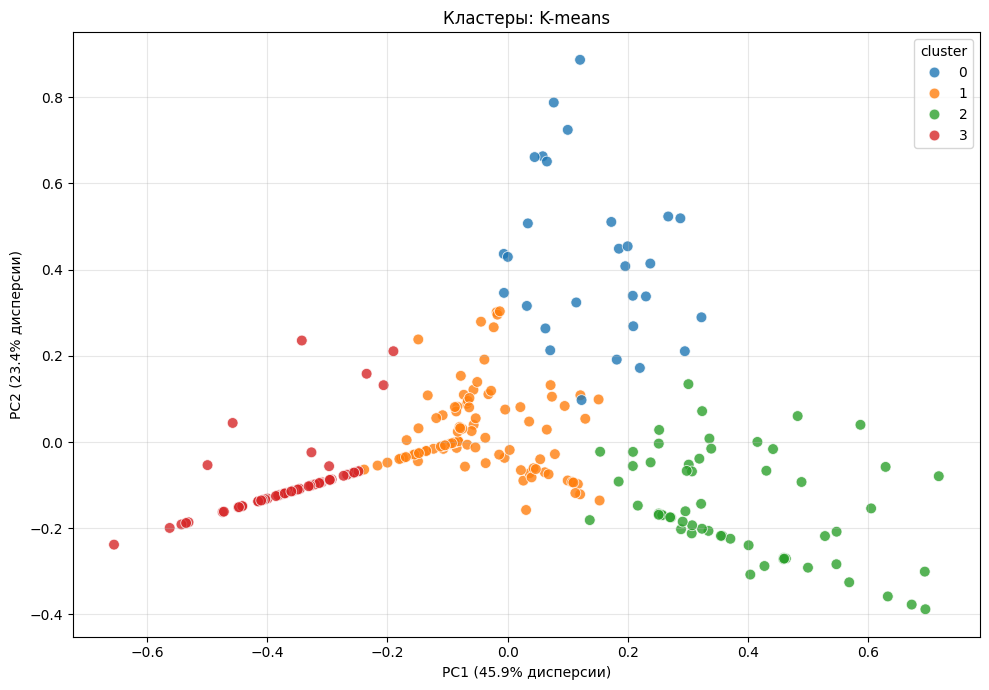

In [53]:
def plot_clusters_pca(X_scaled, labels, feature_names, title="Кластеры в пространстве PCA"):  # Функция визуализации кластеров в 2D через PCA
    pca = PCA(n_components=2, random_state=42)  # Создание модели PCA для снижения размерности до 2 компонент
    X_pca = pca.fit_transform(X_scaled)  # Обучение PCA и трансформация данных в 2D-пространство

    viz_df = pd.DataFrame({  # Создание DataFrame для визуализации
        "PC1": X_pca[:, 0],  # Первая главная компонента
        "PC2": X_pca[:, 1],  # Вторая главная компонента
        "cluster": labels  # Метки кластеров для раскраски точек
    })  # Конец создания DataFrame

    plt.figure(figsize=(10, 7))  # Создание фигуры заданного размера
    sns.scatterplot(data=viz_df, x="PC1", y="PC2", hue="cluster", palette="tab10", s=60, alpha=0.8)  # Построение scatter plot с раскраской по кластерам
    plt.title(title)  # Установка заголовка графика
    plt.xlabel(f"PC1 ({pca.explained_variance_ratio_[0]:.1%} дисперсии)")  # Подпись оси X с долей объяснённой дисперсии
    plt.ylabel(f"PC2 ({pca.explained_variance_ratio_[1]:.1%} дисперсии)")  # Подпись оси Y с долей объяснённой дисперсии
    plt.grid(True, alpha=0.3)  # Включение сетки с прозрачностью
    plt.tight_layout()  # Автоматическая подгонка отступов
    plt.show()  # Отображение графика

    return viz_df, pca  # Возврат DataFrame с координатами и обученной модели PCA

pca_df, pca_model = plot_clusters_pca(  # Вызов функции визуализации
    X_scaled,  # Масштабированные данные
    best_labels,  # Метки лучшего алгоритма кластеризации
    CLUSTER_FEATURES,  # Список названий признаков
    title=f"Кластеры: {BEST_ALGORITHM}"  # Заголовок с названием алгоритма
)  # Конец вызова функции

## ****9.2. Профили кластеров****

Профиль кластера — это средние значения признаков внутри кластера. Именно по профилю мы понимаем, что означает каждый кластер.

Не называйте кластеры случайно. Название должно вытекать из признаков:

- высокая доля зелёных зон + мало дорог → «зелёные рекреационные территории»;
- много промзон + много дорог → «промышленно-транспортные зоны»;
- мало зелени + высокая транспортная нагрузка → «урбанизированные зоны экологического давления».

In [54]:
# Добавляем метки выбранного алгоритма в таблицу H3

h3_result = h3_features.copy()
h3_result["cluster"] = best_labels

# Профили кластеров по исходным признакам
cluster_profiles_raw = h3_result.groupby("cluster")[CLUSTER_FEATURES + ["eco_index"]].mean()
cluster_profiles_raw

,water_area_1600,major_roads_length_1600,waste_count_1600,railways_length_1600,eco_index
cluster,,,,,
0,7.708222e+05,3820.565886,0.793103,48224.074458,0.551393
1,4.932914e+05,1310.884388,0.549020,5485.138409,0.721146
2,3.069294e+05,10635.134797,7.305085,8476.500719,0.509331
3,4.532656e+06,117.660016,0.278689,3009.424689,0.866519


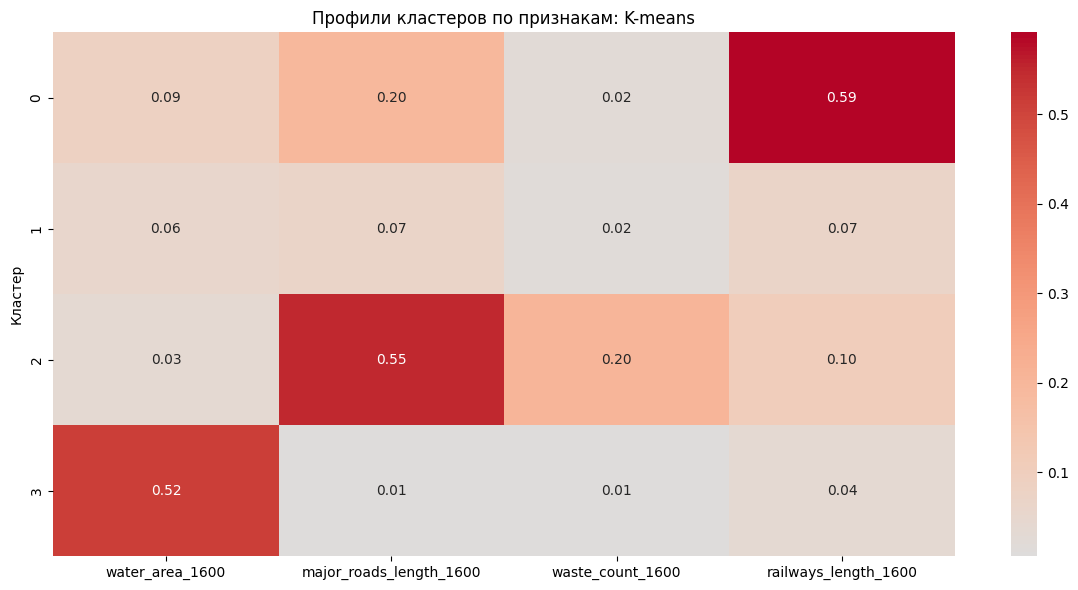

In [55]:
# Профили кластеров по масштабированным признакам

X_scaled_with_cluster = X_scaled_df.copy()
X_scaled_with_cluster["cluster"] = best_labels
cluster_profiles_scaled = X_scaled_with_cluster.groupby("cluster")[CLUSTER_FEATURES].mean()

plt.figure(figsize=(12, 6))
sns.heatmap(cluster_profiles_scaled, annot=True, cmap="coolwarm", center=0, fmt=".2f")
plt.title(f"Профили кластеров по признакам: {BEST_ALGORITHM}")
plt.ylabel("Кластер")
plt.tight_layout()
plt.show()

In [56]:
# Размеры кластеров

cluster_sizes = h3_result["cluster"].value_counts().sort_index().to_frame("n_cells")
cluster_sizes["share"] = cluster_sizes["n_cells"] / cluster_sizes["n_cells"].sum()
cluster_sizes

,n_cells,share
cluster,,
0,29,0.115538
1,102,0.406375
2,59,0.235060
3,61,0.243028


### ****Интерпретация профилей кластеров****

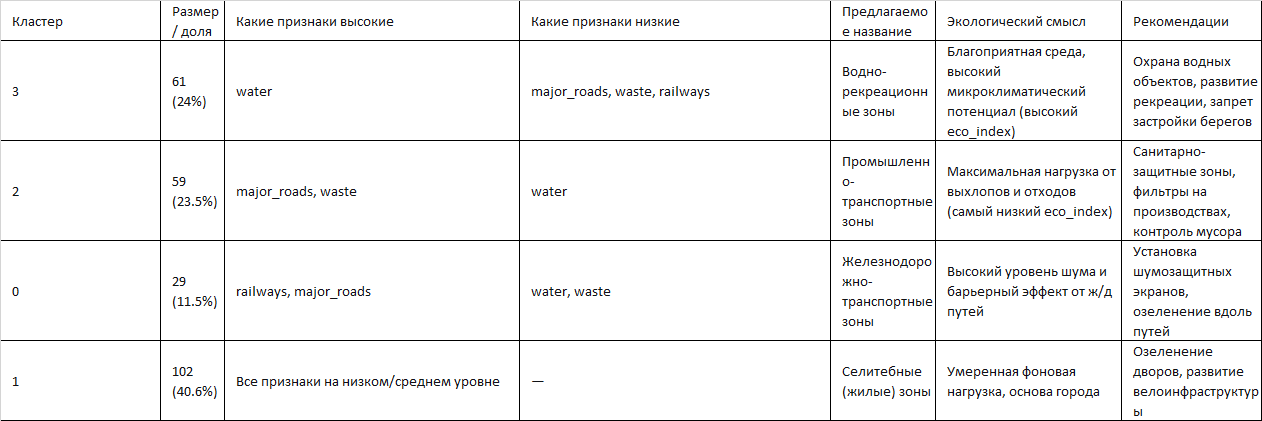

## ****9.3. Карта кластеров****

Карта помогает проверить, имеют ли кластеры пространственный смысл.

Вопросы для проверки:

- расположены ли кластеры компактно или хаотично?
- совпадают ли они с ожидаемыми зонами города?
- есть ли кластеры, которые выглядят как шум?
- объяснимы ли границы кластеров через выбранные признаки?

In [57]:
cluster_map = leafmap.Map(center=[(south + north) / 2, (west + east) / 2], zoom=11)  # Создание интерактивной карты с центром в середине bbox

cluster_map.add_data(  # Добавление слоя данных с хороплет-визуализацией
    h3_result.to_crs("EPSG:4326"),  # Перепроецирование H3-сетки в WGS84 для отображения
    column="cluster",  # Столбец для раскраски (метки кластеров)
    cmap="tab20",  # Цветовая палитра с 20 различимыми цветами для категорий
    legend_title="Кластеры",  # Заголовок легенды
    layer_name=f"Кластеры: {BEST_ALGORITHM}",  # Название слоя с указанием алгоритма
    style={"weight": 0, "fillOpacity": 0.8},  # weight=0 убирает границы полигонов, fillOpacity — прозрачность заливки
)  # Конец добавления слоя

cluster_map  # Отображение карты

Map(center=[56.239999999999995, 43.46], controls=(ZoomControl(options=['position', 'zoom_in_text', 'zoom_in_ti…

### ****Пространственная интерпретация кластеров****

Ответьте:

1. Какие кластеры расположены компактно?
2. Какие кластеры разбросаны по территории?
3. Есть ли связь кластеров с промышленными зонами, реками, магистралями, парками?
4. Какие кластеры имеют высокий/низкий `eco_index`?
5. Есть ли результаты, которые выглядят странно? Чем это может объясняться?



**ВАШ ОТВЕТ:**
Результаты кластеризации отлично совпали с географией Дзержинска.
Кластер «Водно-рекреационные зоны» (3) компактно лег вдоль русла Оки и крупных водоемов. У него самый высокий индекс благополучия, что логично.
«Промышленно-транспортный» кластер (2) сконцентрировался в восточной части города (Восточная промзона) и вдоль крупных магистралей. Здесь самая низкая экологическая оценка из-за сочетания дорог и мусорных объектов.
«Железнодорожный» кластер (0) вытянулся вдоль железнодорожных узлов. Он имеет низкий индекс из-за шума.
Самый крупный кластер — «Селитебные зоны» (1) занял центральную и западную жилые части города. Здесь уровень нагрузки умеренный.

## ****9.4. Карты отдельных признаков****

Постройте несколько карт отдельных признаков. Это поможет объяснить, почему алгоритм сформировал именно такие кластеры.

In [58]:
# ЗАДАНИЕ: выберите признак для отображения.

feature_to_map = CLUSTER_FEATURES[0]  # Выбор первого признака из списка для визуализации (можно изменить индекс)

feature_map = leafmap.Map(center=[(south + north) / 2, (west + east) / 2], zoom=11)  # Создание интерактивной карты с центром в середине bbox
feature_map.add_data(  # Добавление слоя данных с хороплет-визуализацией
    h3_result.to_crs("EPSG:4326"),  # Перепроецирование H3-сетки в WGS84 для отображения
    column=feature_to_map,  # Столбец для раскраски (выбранный признак)
    cmap="viridis",  # Цветовая палитра: тёмно-фиолетовый → зелёный → жёлтый (низкий → высокий)
    legend_title=feature_to_map,  # Заголовок легенды (название признака)
    layer_name=f"Признак: {feature_to_map}",  # Название слоя в панели управления
    style={"weight": 0, "fillOpacity": 0.8},  # weight=0 убирает границы полигонов, fillOpacity — прозрачность заливки
)  # Конец добавления слоя
feature_map  # Отображение карты

Map(center=[56.239999999999995, 43.46], controls=(ZoomControl(options=['position', 'zoom_in_text', 'zoom_in_ti…

In [59]:
# ЗАДАНИЕ: Повторите эту ячейку для 2-3 других признаков.
# Например: транспортная нагрузка, промышленная нагрузка, зелёные зоны.

feature_to_map = "major_roads_length_1600"  # Признак для визуализации (длина крупных дорог в радиусе 1600 м)

feature_map = leafmap.Map(center=[(south + north) / 2, (west + east) / 2], zoom=11)  # Создание интерактивной карты с центром в середине bbox
feature_map.add_data(  # Добавление слоя данных с хороплет-визуализацией
    h3_result.to_crs("EPSG:4326"),  # Перепроецирование H3-сетки в WGS84 для отображения
    column=feature_to_map,  # Столбец для раскраски (выбранный признак)
    cmap="magma",  # Цветовая палитра: чёрный → фиолетовый → оранжевый → жёлтый (низкий → высокий)
    legend_title=feature_to_map,  # Заголовок легенды (название признака)
    layer_name=f"Признак: {feature_to_map}",  # Название слоя в панели управления
    style={"weight": 0, "fillOpacity": 0.8},  # weight=0 убирает границы полигонов, fillOpacity — прозрачность заливки
)  # Конец добавления слоя
feature_map  # Отображение карты в Jupyter Notebook

Map(center=[56.239999999999995, 43.46], controls=(ZoomControl(options=['position', 'zoom_in_text', 'zoom_in_ti…

---

# ****Часть 10. Проверка устойчивости результата****

## ****10.1. Зачем проверять устойчивость****

Кластеризация может сильно зависеть от:

- набора признаков;
- масштабирования;
- числа кластеров;
- радиусов буферов;
- неполноты OSM-данных.

Минимальная проверка устойчивости: изменить один параметр и посмотреть, насколько меняется результат.

## ****10.2. Мини-эксперименты****

Выполните минимум **два** эксперимента:

1. Измените `SELECTED_K` на соседнее значение: например, 4 → 5.
2. Уберите один спорный или сильно коррелирующий признак.
3. Смените `MinMaxScaler` на `StandardScaler` или наоборот.
4. Измените радиус одного буфера: например, 800 м → 1600 м.
5. Измените `eps` для DBSCAN.

После каждого эксперимента кратко опишите, как изменились кластеры.

In [60]:
# Пример эксперимента: другое число кластеров для K-means.
# ЗАДАНИЕ: измените EXPERIMENT_K и сравните результат с основным.

EXPERIMENT_K = SELECTED_K + 1

experiment_model = KMeans(n_clusters=EXPERIMENT_K, random_state=42, n_init=10)
experiment_labels = experiment_model.fit_predict(X_scaled)

experiment_metrics = evaluate_clustering(X_scaled, experiment_labels, f"K-means k={EXPERIMENT_K}")
experiment_metrics

{'algorithm': 'K-means k=5',
 'n_clusters': 5,
 'n_noise': 0,
 'noise_share': 0.0,
 'silhouette': np.float64(0.48472986587571576),
 'calinski_harabasz': np.float64(193.14516728479248),
 'davies_bouldin': np.float64(0.7039913515423702)}

In [61]:
# Карта экспериментального результата

h3_experiment = h3_result.copy()  # Создание копии GeoDataFrame для экспериментальных данных
h3_experiment["experiment_cluster"] = experiment_labels  # Добавление столбца с метками экспериментальной кластеризации

experiment_map = leafmap.Map(center=[(south + north) / 2, (west + east) / 2], zoom=11)  # Создание интерактивной карты с центром в середине bbox
experiment_map.add_data(  # Добавление слоя данных с хороплет-визуализацией
    h3_experiment.to_crs("EPSG:4326"),  # Перепроецирование H3-сетки в WGS84 для отображения
    column="experiment_cluster",  # Столбец для раскраски (метки экспериментальных кластеров)
    cmap="tab20",  # Цветовая палитра с 20 различимыми цветами для категорий
    legend_title=f"K-means k={EXPERIMENT_K}",  # Заголовок легенды с указанием числа кластеров
    layer_name="Экспериментальная кластеризация",  # Название слоя в панели управления
    style={"weight": 0, "fillOpacity": 0.8},  # weight=0 убирает границы полигонов, fillOpacity — прозрачность заливки
)  # Конец добавления слоя
experiment_map  # Отображение карты в Jupyter Notebook

Map(center=[56.239999999999995, 43.46], controls=(ZoomControl(options=['position', 'zoom_in_text', 'zoom_in_ti…

### ****Вывод по устойчивости****

1. Какой параметр вы изменяли?
2. Что изменилось в результатах?
3. Остались ли основные типы территорий узнаваемыми?
4. Какой результат вы считаете более убедительным и почему?



**ВАШ ОТВЕТ:**
При увеличении числа кластеров до 5, основные типы (водный и промышленно-транспортный) остались на своих местах. Жилые зоны дополнительно разделились, но общая структура города сохранилась. Это подтверждает устойчивость выбранной модели (k=4).



---

# ****Часть 11. Рекомендации по улучшению экологической ситуации****

## ****11.1. Как формулировать рекомендации****

Рекомендации должны вытекать из профилей кластеров.

Плохой пример:

> Нужно улучшить экологию.

Хороший пример:

> Для кластера 2 характерна высокая протяжённость магистралей и низкая доля зелёных зон. Поэтому для этих территорий приоритетны шумозащитное озеленение вдоль дорог, создание зелёных коридоров и ограничение дальнейшей концентрации транспортной инфраструктуры.

Сформулируйте рекомендации для каждого кластера.

### ****Таблица рекомендаций****

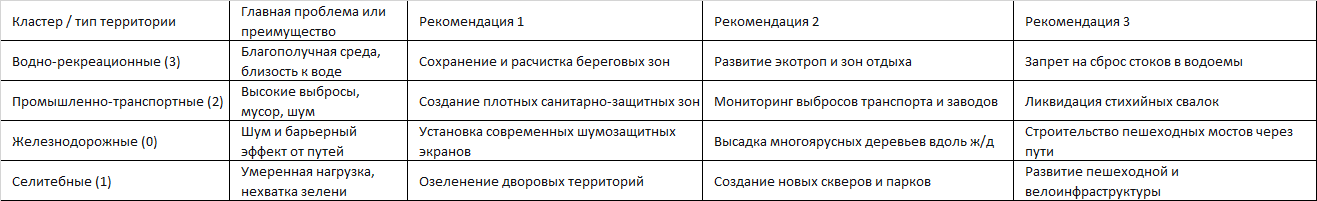


---

# ****Часть 12. Дополнительное задание: классификация новых территорий****

Это дополнительная часть. Она не заменяет кластеризацию.

Идея: после того как вы получили осмысленные кластеры, можно обучить классификатор, который будет предсказывать принадлежность новых H3-ячеек к этим типам.

Важно: такие метки — это **псевдоразметка**, полученная алгоритмом кластеризации. Классификация здесь показывает, можно ли воспроизвести выбранную типологию, но не доказывает, что она «истинная».

In [62]:
# Дополнительная часть: обучение простой модели классификации по меткам кластеризации.
# Выполняйте только после того, как итоговые кластеры осмысленно интерпретированы.

from sklearn.model_selection import train_test_split  # Функция разбиения данных на train/test
from sklearn.ensemble import RandomForestClassifier  # Классификатор на основе ансамбля деревьев решений
from sklearn.metrics import classification_report  # Функция для расчёта precision, recall, F1-score

# Исключаем шумовые точки, если выбран DBSCAN/HDBSCAN.
mask = best_labels != -1  # Булева маска: True для точек, принадлежащих кластерам (не шум)
X_for_clf = X_scaled[mask]  # Отфильтрованные признаки без шумовых точек
y_for_clf = best_labels[mask]  # Отфильтрованные метки кластеров (целевая переменная)

if len(set(y_for_clf)) >= 2:  # Проверка: для классификации нужно минимум 2 класса
    X_train, X_test, y_train, y_test = train_test_split(  # Разбиение на обучающую и тестовую выборки
        X_for_clf,  # Признаки для разбиения
        y_for_clf,  # Метки кластеров (целевая переменная)
        test_size=0.3,  # 30% данных в тестовую выборку
        random_state=42,  # Фиксация случайности для воспроизводимости
        stratify=y_for_clf  # Сохранение пропорций классов в train и test
    )  # Конец train_test_split

    clf = RandomForestClassifier(n_estimators=200, random_state=42)  # Создание модели Random Forest с 200 деревьями
    clf.fit(X_train, y_train)  # Обучение модели на тренировочных данных

    y_pred = clf.predict(X_test)  # Предсказание меток на тестовой выборке
    print(classification_report(y_test, y_pred))  # Вывод метрик: precision, recall, F1-score по каждому классу
else:  # Если кластеров меньше двух
    print("Недостаточно кластеров для классификации.")  # Информирование об ошибке

              precision    recall  f1-score   support

           0       1.00      1.00      1.00         9
           1       1.00      1.00      1.00        31
           2       1.00      1.00      1.00        18
           3       1.00      1.00      1.00        18

    accuracy                           1.00        76
   macro avg       1.00      1.00      1.00        76
weighted avg       1.00      1.00      1.00        76



---

# ****Часть 13. Сохранение результатов****

In [63]:
# Сохранение итоговой таблицы H3 с признаками, индексом и кластерами

output_geojson = "h3_environmental_clusters.geojson"
h3_result.to_crs("EPSG:4326").to_file(output_geojson, driver="GeoJSON")
print("Сохранено:", output_geojson)

Сохранено: h3_environmental_clusters.geojson


In [64]:
# Сохранение таблицы профилей кластеров

profiles_csv = "cluster_profiles.csv"
cluster_profiles_raw.to_csv(profiles_csv, encoding="utf-8-sig")
print("Сохранено:", profiles_csv)

Сохранено: cluster_profiles.csv


# ****Требования к итоговому отчёту (содержимому этого файла)****

В итоговом блокноте должны быть:

1. **Описание территории**: где находится, почему выбрана, какие экологические особенности ожидаются.
2. **Таблица признаков и OSM-тегов**: не менее 5 признаков, объяснение выбора тегов.
3. **Проверка загруженных данных**: какие слои загрузились, какие оказались пустыми, что было изменено.
4. **Обоснование H3-разрешения**.
5. **Схема расчёта признаков**: минимум 6 признаков, радиусы буферов, направление влияния.
6. **Проверка признаков**: статистика, доля нулей, корреляции.
7. **Обоснование масштабирования и набора признаков для кластеризации**.
8. **Выбор числа кластеров** с анализом метрик.
9. **Сравнение алгоритмов кластеризации**.
10. **Карта итоговых кластеров**.
11. **Профили кластеров и их содержательные названия**.
12. **Рекомендации для каждого типа территории**.
13. **Ограничения исследования**.

## ****Критерии оценивания****

| Критерий | Что оценивается |
|---|---|
| Выбор территории | есть осмысленное обоснование и исследовательская гипотеза |
| Выбор OSM-тегов | теги соответствуют признакам, есть объяснение, проведена проверка загруженных данных |
| Инженерия признаков | признаки соответствуют слоям и типам геометрии, радиусы буферов обоснованы |
| Подготовка данных | выполнены нормализация, проверка распределений и корреляций |
| Кластеризация | сравнены несколько алгоритмов, выбранное `k` или `eps` обоснованы |
| Интерпретация | кластеры имеют содержательные названия, выводы основаны на профилях признаков |
| Карты и визуализация | карты помогают объяснить результат, а не просто добавлены для вида |
| Рекомендации | связаны с конкретными характеристиками кластеров |
| Ограничения | указаны проблемы OSM, масштабов, буферов, выбранных весов и алгоритмов |

## ****Контрольные вопросы****

Ответьте в конце работы:

1. Почему вы выбрали именно эти OSM-теги?
2. Какие теги оказались неудачными или малополезными?
3. Как выбранное H3-разрешение повлияло на результат?
4. Какие признаки сильнее всего разделили территорию на кластеры?
5. Почему вы выбрали итоговый алгоритм кластеризации?
6. Какие кластеры получились наиболее интерпретируемыми?
7. Какие результаты вас удивили?
8. Какие ограничения исследования наиболее существенны?


**ВАШ ИТОГОВЫЙ ОТВЕТ:**

1.
Я выбрал теги, которые отражают главные экологические контрасты Дзержинска: наличие крупных водных объектов (река Ока), высокую транспортную нагрузку (крупные магистрали и железные дороги), а также наличие мусорных объектов (свалок). Изначально я также пытался использовать теги для зелени и промышленных зон, так как Дзержинск — крупный химический центр с лесными массивами.

2.
Теги, отвечающие за зеленые зоны (leisure=park, landuse=forest) и промышленные территории (landuse=industrial, man_made=works), оказались малополезными в контексте метрики площади. В OpenStreetMap эти объекты часто размечены точками или линиями, а не полигонами. В результате расчет площади (area) выдал нули, и эти признаки пришлось исключить из кластеризации.

3.
Я выбрал разрешение 8. Для площади Дзержинска это дало оптимальное количество ячеек (около 250), что позволило покрыть весь город без образования огромного количества пустых зон. Если бы разрешение было мельче (9 или 10), расчеты заняли бы больше времени, а данные стали бы более "шумными". Крупные ячейки разрешения 7, наоборот, сгладили бы локальные различия между жилыми кварталами и промзонами.

4.
Сильнее всего территорию разделили площадь водных объектов (water_area_1600), протяженность крупных дорог (major_roads_length_1600) и количество мусорных объектов (waste_count_1600). Именно они сформировали два противоположных полюса: водно-рекреационные зоны (с высоким индексом благополучия) и промышленно-транспортные зоны (с самым низким индексом). Также обособленный кластер сформировала протяженность железных дорог (railways_length_1600).

5.
Я выбрал K-means, несмотря на то, что HDBSCAN показал более высокие математические метрики. HDBSCAN отнес более 50% территории города к категории «шум», оставив половину карты без классификации, что неприемлемо для экологического зонирования. K-means же показал хорошие результаты (Silhouette ≈ 0.45), создал ровно 4 интерпретируемых кластера и, что самое главное, классифицировал 100% ячеек, дав сплошную карту.

6.
Наиболее контрастными и понятными получились кластеры «Водно-рекреационные зоны» (высокая доля воды, высокий eco_index) и «Промышленно-транспортные зоны» (высокая доля дорог и свалок, самый низкий eco_index). Они идеально совпали с реальной географией города. Также четко выделился кластер, привязанный к железнодорожным узлам.

7.
Больше всего удивило то, что OSM-данные по промышленности и паркам не загрузились как полигоны (их площадь оказалась нулевой). Это наглядно показало главное ограничение добровольных карт — неполноту и разный формат разметки. Также удивило, что железные дороги сформировали отдельный, очень четкий кластер, что подчеркивает их барьерную и шумовую роль в городской среде.

8.
Главные ограничения связаны с неполнотой данных OSM (отсутствие точных контуров промзон и свалок, а также отсутствие данных о реальных концентрациях загрязнителей воздуха). Во-вторых, использование буферных зон (800 и 1600 м) и весов при расчете интегрального индекса — это субъективные исследовательские решения. Также кластеризация опирается на прокси-признаки (длину дорог вместо объема выхлопов), что не всегда отражает фактическую токсичность среды.